<div style="background:linear-gradient(135deg,#1a3a5c 0%,#2d6a9f 100%);padding:28px;border-radius:10px;color:white">

# Projet 11 — Étude de marché internationale
## Livrable 2 · ACP, clustering et recommandations

**Client** : *La poule qui chante* — élevage et vente de poulets sous label bio  
**Commanditaire** : Patrick, PDG  
**Mission** : regrouper les pays et recommander des cibles d'export

</div>

---

### Objectif de ce notebook

À partir du jeu de données propre produit au livrable 1 :

1. réduire la dimension par une **analyse en composantes principales (ACP)** ;
2. regrouper les pays par **deux méthodes de classification** — classification ascendante
   hiérarchique (CAH) puis k-means ;
3. **comparer** les deux partitions et caractériser les groupes obtenus ;
4. formuler des **recommandations de pays** argumentées.

### Sommaire

| § | Étape |
|---|---|
| 1 | Configuration et chargement |
| 2 | Préparation : sélection des variables et centrage-réduction |
| 3 | ACP — éboulis des valeurs propres et choix du nombre d'axes |
| 4 | ACP — cercle des corrélations |
| 5 | ACP — projection des individus |
| 6 | ACP — qualité de représentation et contributions |
| 7 | Interprétation des axes factoriels |
| 8 | Classification ascendante hiérarchique (CAH) |
| 9 | K-means — recherche du nombre optimal de clusters |
| 10 | Comparaison des deux méthodes |
| 11 | Données brutes ou données ACP pour le clustering ? |
| 12 | Caractérisation des clusters |
| 13 | Répartition géographique |
| 14 | Recommandations pour La poule qui chante |
| 15 | Export |


---
## 1. Configuration et chargement


In [128]:
# =============================================================================
# 1. CONFIGURATION
# =============================================================================

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")
PALETTE = ["#2d6a9f", "#e07a3f", "#4a9d5f", "#b5485d", "#8562a8", "#7d6355", "#3a9fa8"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

RAW, CLEAN = "../Data/raw/", "../Data/clean/"
RANDOM_STATE = 42          # graine fixe : résultats strictement reproductibles

def titre(txt, char="=", larg=78):
    print(char * larg); print(txt); print(char * larg)

titre("CONFIGURATION TERMINÉE")
print(f"pandas {pd.__version__} | numpy {np.__version__}")


CONFIGURATION TERMINÉE
pandas 2.3.3 | numpy 2.3.5


In [129]:
# =============================================================================
# 1.2  CHARGEMENT DU JEU DE DONNÉES PRÉPARÉ
# =============================================================================

df = pd.read_csv(CLEAN + "donnees_pays_2017.csv")
dico = pd.read_csv(CLEAN + "dictionnaire_variables.csv")

titre("JEU DE DONNÉES ISSU DU LIVRABLE 1")
print(f"{df.shape[0]} pays x {df.shape[1]} colonnes")
print(f"Valeurs manquantes : {int(df.isna().sum().sum())}")
print(f"Doublons           : {int(df.duplicated(subset='iso3').sum())}\n")
display(df.head())


JEU DE DONNÉES ISSU DU LIVRABLE 1
168 pays x 23 colonnes
Valeurs manquantes : 0
Doublons           : 0



,pays,iso3,continent,population,dispo_volaille_kg,production_volaille,import_volaille,export_volaille,dispo_kcal_totale,proteines_animales,pib_habitant,croissance_pib,pop_urbaine_pct,inflation,taux_dependance_import,taux_autosuffisance,croissance_pop_2010_2018,part_proteines_animales,log_population,log_production_volaille,log_import_volaille,log_export_volaille,log_pib_habitant
0,Afghanistan,AFG,Asie,"36,296.11",1.53,28.00,29.00,0.00,"1,997.00",10.56,525.47,2.65,24.84,4.98,50.88,49.12,27.36,19.52,10.50,3.37,3.40,0.00,6.27
1,Afrique du Sud,ZAF,Afrique,"57,009.76",35.69,"1,667.00",514.00,63.00,"2,987.00",34.56,"6,618.34",1.16,63.33,5.19,24.27,78.71,12.84,41.46,10.95,7.42,6.24,4.16,8.80
2,Albanie,ALB,Europe,"2,884.17",16.36,13.00,38.00,0.00,"3,400.00",66.33,"5,006.36",3.28,55.98,1.99,80.85,27.66,-2.21,55.51,7.97,2.64,3.66,0.00,8.52
3,Algérie,DZA,Afrique,"41,389.19",6.38,275.00,2.00,0.00,"3,345.00",25.70,"4,554.67",1.50,71.32,5.59,0.72,99.28,17.37,27.68,10.63,5.62,1.10,0.00,8.42
4,Allemagne,DEU,Europe,"82,658.41",19.47,"1,514.00",842.00,646.00,"3,559.00",63.09,"45,553.93",2.80,80.98,1.51,48.42,87.06,2.84,60.62,11.32,7.32,6.74,6.47,10.73


---
## 2. Préparation : sélection des variables et centrage-réduction

### Quelles variables entrent dans l'ACP ?

On retient les variables **de niveau** et **de structure**, en privilégiant les versions
logarithmiques construites au livrable 1 pour les variables de volume très asymétriques.

### Pourquoi centrer et réduire ?

L'ACP travaille sur la **variance**. Or nos variables n'ont ni la même unité ni le même
ordre de grandeur :

| Variable | Unité | Ordre de grandeur |
|---|---|---|
| `pib_habitant` | USD | de 200 à 100 000 |
| `dispo_volaille_kg` | kg/pers/an | de 0 à 60 |
| `pop_urbaine_pct` | % | de 10 à 100 |

Sans traitement, le PIB écraserait tout : sa variance est mille fois supérieure à celle
de la consommation de volaille. L'ACP décrirait la variance du PIB et rien d'autre.

**Centrer** = soustraire la moyenne, pour que chaque variable soit centrée sur 0.
**Réduire** = diviser par l'écart-type, pour que chaque variable ait un écart-type de 1.

Après ce traitement, toutes les variables pèsent le même poids et sont exprimées
dans la même unité : **l'écart-type**.


In [130]:
# =============================================================================
# 2. PRÉPARATION DES DONNÉES
# =============================================================================

# Variables du modèle : version log si elle existe, version brute sinon
BASE = ["population", "dispo_volaille_kg", "production_volaille", "import_volaille",
        "export_volaille", "dispo_kcal_totale", "proteines_animales",
        "pib_habitant", "croissance_pib", "pop_urbaine_pct", "inflation",
        "taux_dependance_import", "taux_autosuffisance",
        "croissance_pop_2010_2018", "part_proteines_animales"]

VARS = [("log_" + c if "log_" + c in df.columns else c) for c in BASE]

X = df[VARS].copy()
PAYS = df["pays"].values

titre("2.1  VARIABLES RETENUES POUR L'ACP")
print(f"{len(VARS)} variables, {len(X)} individus (pays)\n")
for i, v in enumerate(VARS, 1):
    print(f"   {i:>2}. {v}")


2.1  VARIABLES RETENUES POUR L'ACP
15 variables, 168 individus (pays)

    1. log_population
    2. dispo_volaille_kg
    3. log_production_volaille
    4. log_import_volaille
    5. log_export_volaille
    6. dispo_kcal_totale
    7. proteines_animales
    8. log_pib_habitant
    9. croissance_pib
   10. pop_urbaine_pct
   11. inflation
   12. taux_dependance_import
   13. taux_autosuffisance
   14. croissance_pop_2010_2018
   15. part_proteines_animales


In [131]:
# --- 2.2 Centrage-réduction ---------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=VARS, index=PAYS)

titre("2.2  VÉRIFICATION DU CENTRAGE-RÉDUCTION")
verif = pd.DataFrame({
    "moyenne_avant": X.mean().round(2),
    "écart_type_avant": X.std().round(2),
    "moyenne_après": X_scaled_df.mean().round(6),
    "écart_type_après": X_scaled_df.std(ddof=0).round(6),
})
display(verif)
print("\nAprès traitement : moyenne = 0 et écart-type = 1 pour toutes les variables.")
print("Les variables sont désormais comparables et pèsent le même poids dans l'ACP.")


2.2  VÉRIFICATION DU CENTRAGE-RÉDUCTION


,moyenne_avant,écart_type_avant,moyenne_après,écart_type_après
log_population,8.98,1.96,0.00,1.00
dispo_volaille_kg,20.41,15.87,0.00,1.00
log_production_volaille,4.24,2.36,-0.00,1.00
log_import_volaille,2.95,1.87,-0.00,1.00
log_export_volaille,1.59,2.17,-0.00,1.00
dispo_kcal_totale,"2,860.54",455.01,0.00,1.00
proteines_animales,37.09,20.38,0.00,1.00
log_pib_habitant,8.72,1.39,0.00,1.00
croissance_pib,3.31,3.32,0.00,1.00
pop_urbaine_pct,59.16,21.59,-0.00,1.00



Après traitement : moyenne = 0 et écart-type = 1 pour toutes les variables.
Les variables sont désormais comparables et pèsent le même poids dans l'ACP.


---
## 3. ACP — éboulis des valeurs propres et choix du nombre d'axes

L'ACP construit de nouvelles variables, les **composantes principales**, qui sont des
combinaisons des variables d'origine. La première capture le maximum de variance possible,
la deuxième le maximum de ce qui reste, et ainsi de suite.

L'**éboulis des valeurs propres** (*scree plot*) montre combien d'information chaque axe porte.
Trois critères usuels pour choisir combien d'axes retenir :

| Critère | Règle |
|---|---|
| **Kaiser** | conserver les axes de valeur propre > 1 (un axe doit porter plus qu'une variable seule) |
| **Coude** | s'arrêter là où la courbe décroche |
| **Variance cumulée** | atteindre 70-80 % de l'information totale |


In [132]:
# =============================================================================
# 3. ACP — VALEURS PROPRES
# =============================================================================

pca = PCA(n_components=len(VARS), random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)

vp = pca.explained_variance_
var_ratio = pca.explained_variance_ratio_ * 100
var_cum = np.cumsum(var_ratio)

tab_vp = pd.DataFrame({
    "axe": [f"F{i+1}" for i in range(len(vp))],
    "valeur_propre": vp.round(3),
    "variance_%": var_ratio.round(2),
    "variance_cumulée_%": var_cum.round(2),
    "critère_Kaiser": np.where(vp > 1, "retenu", "-"),
})

titre("3.1  VALEURS PROPRES ET VARIANCE EXPLIQUÉE")
display(tab_vp)

n_kaiser = int((vp > 1).sum())
n_70 = int(np.argmax(var_cum >= 70) + 1)
print(f"\nCritère de Kaiser (valeur propre > 1) : {n_kaiser} axes")
print(f"Seuil de 70 % de variance cumulée     : {n_70} axes")


3.1  VALEURS PROPRES ET VARIANCE EXPLIQUÉE


,axe,valeur_propre,variance_%,variance_cumulée_%,critère_Kaiser
0,F1,5.60,37.14,37.14,retenu
1,F2,3.19,21.14,58.27,retenu
2,F3,1.46,9.69,67.97,retenu
3,F4,1.12,7.41,75.38,retenu
4,F5,0.75,4.98,80.36,-
5,F6,0.70,4.64,85.01,-
6,F7,0.59,3.93,88.94,-
7,F8,0.47,3.10,92.04,-
8,F9,0.34,2.23,94.26,-
9,F10,0.30,1.96,96.23,-



Critère de Kaiser (valeur propre > 1) : 4 axes
Seuil de 70 % de variance cumulée     : 4 axes


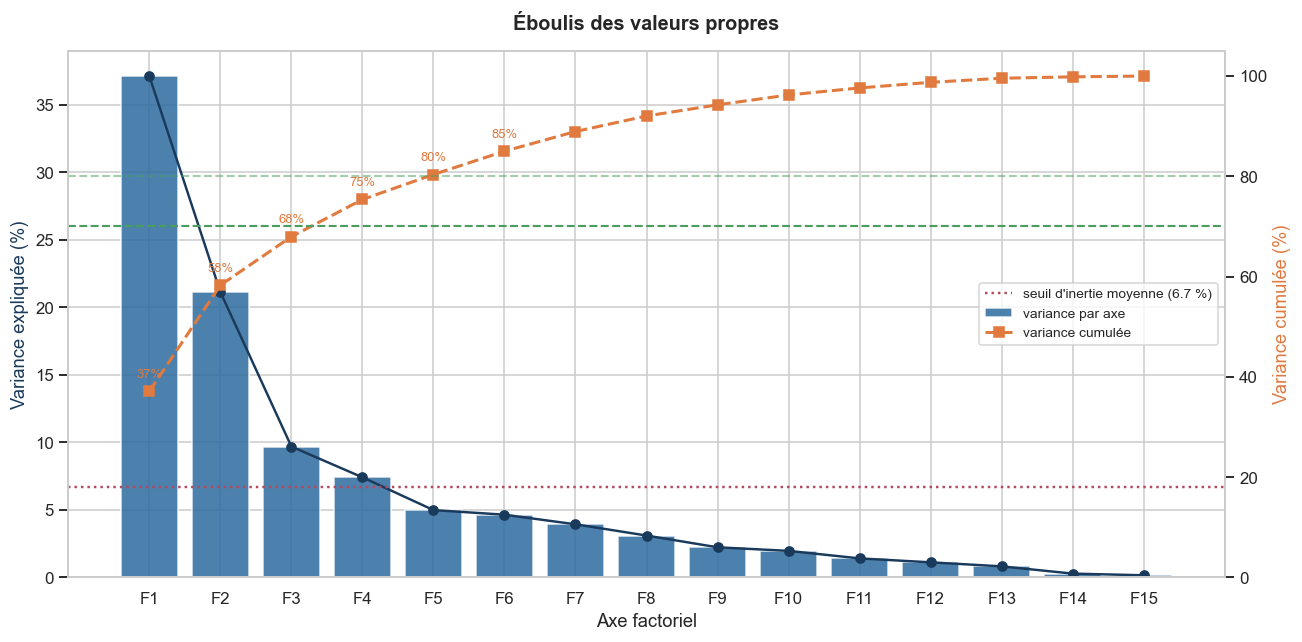

In [133]:
# --- 3.2 Éboulis des valeurs propres ------------------------------------------

fig, ax1 = plt.subplots(figsize=(12, 6))
x = np.arange(1, len(vp) + 1)

ax1.bar(x, var_ratio, color="#2d6a9f", alpha=.85, edgecolor="white", label="variance par axe")
ax1.plot(x, var_ratio, "o-", color="#1a3a5c", lw=1.6, ms=6)
ax1.axhline(100 / len(VARS), color="#b5485d", ls=":", lw=1.6,
            label=f"seuil d'inertie moyenne ({100/len(VARS):.1f} %)")
ax1.set_xlabel("Axe factoriel")
ax1.set_ylabel("Variance expliquée (%)", color="#1a3a5c")
ax1.set_xticks(x)
ax1.set_xticklabels([f"F{i}" for i in x])

ax2 = ax1.twinx()
ax2.plot(x, var_cum, "s--", color="#e07a3f", lw=2, ms=6, label="variance cumulée")
ax2.axhline(70, color="#4a9d5f", ls="--", lw=1.4)
ax2.axhline(80, color="#4a9d5f", ls="--", lw=1.4, alpha=.5)
ax2.set_ylabel("Variance cumulée (%)", color="#e07a3f")
ax2.set_ylim(0, 105)
ax2.grid(False)

for i, (v, c) in enumerate(zip(var_ratio, var_cum), 1):
    if i <= 6:
        ax2.annotate(f"{c:.0f}%", (i, c), textcoords="offset points",
                     xytext=(0, 9), ha="center", fontsize=8.5, color="#e07a3f")

lignes1, lab1 = ax1.get_legend_handles_labels()
lignes2, lab2 = ax2.get_legend_handles_labels()
ax1.legend(lignes1 + lignes2, lab1 + lab2, loc="center right", fontsize=9)
plt.title("Éboulis des valeurs propres", pad=14)
plt.tight_layout()
plt.show()


In [134]:
# --- 3.3 Décision : nombre d'axes retenus -------------------------------------

N_AXES = 4          # décision argumentée ci-dessous

titre("3.3  NOMBRE D'AXES RETENUS")
print(f"Axes conservés : {N_AXES}")
print(f"Variance cumulée sur ces {N_AXES} axes : {var_cum[N_AXES-1]:.1f} %")
print()
print("Justification :")
print(f"  • critère de Kaiser  : {n_kaiser} axes ont une valeur propre > 1")
print(f"  • coude de l'éboulis : décrochement net après F2-F3")
print(f"  • variance cumulée   : {var_cum[N_AXES-1]:.1f} %, au-delà du seuil usuel de 70 %")
print()
print(f"On retient {N_AXES} axes : le compromis entre information conservée")
print("et simplicité d'interprétation. Les axes F1-F2 seront commentés en priorité,")
print(f"F3-F4 servant de complément d'analyse.")

coords_ret = coords[:, :N_AXES]
coords_df = pd.DataFrame(coords_ret, columns=[f"F{i+1}" for i in range(N_AXES)],
                         index=PAYS)


3.3  NOMBRE D'AXES RETENUS
Axes conservés : 4
Variance cumulée sur ces 4 axes : 75.4 %

Justification :
  • critère de Kaiser  : 4 axes ont une valeur propre > 1
  • coude de l'éboulis : décrochement net après F2-F3
  • variance cumulée   : 75.4 %, au-delà du seuil usuel de 70 %

On retient 4 axes : le compromis entre information conservée
et simplicité d'interprétation. Les axes F1-F2 seront commentés en priorité,
F3-F4 servant de complément d'analyse.


---
## 4. ACP — cercle des corrélations

Le cercle des corrélations montre **comment chaque variable d'origine se projette** sur les
nouveaux axes. Trois règles de lecture :

| Observation | Interprétation |
|---|---|
| flèche **longue** (proche du cercle) | variable **bien représentée** sur ce plan |
| flèches dans la **même direction** | variables **corrélées positivement** |
| flèches **opposées** | variables **corrélées négativement** |
| flèches à **90°** | variables **indépendantes** |
| flèche **courte** (proche du centre) | variable **mal représentée** — ne pas l'interpréter ici |


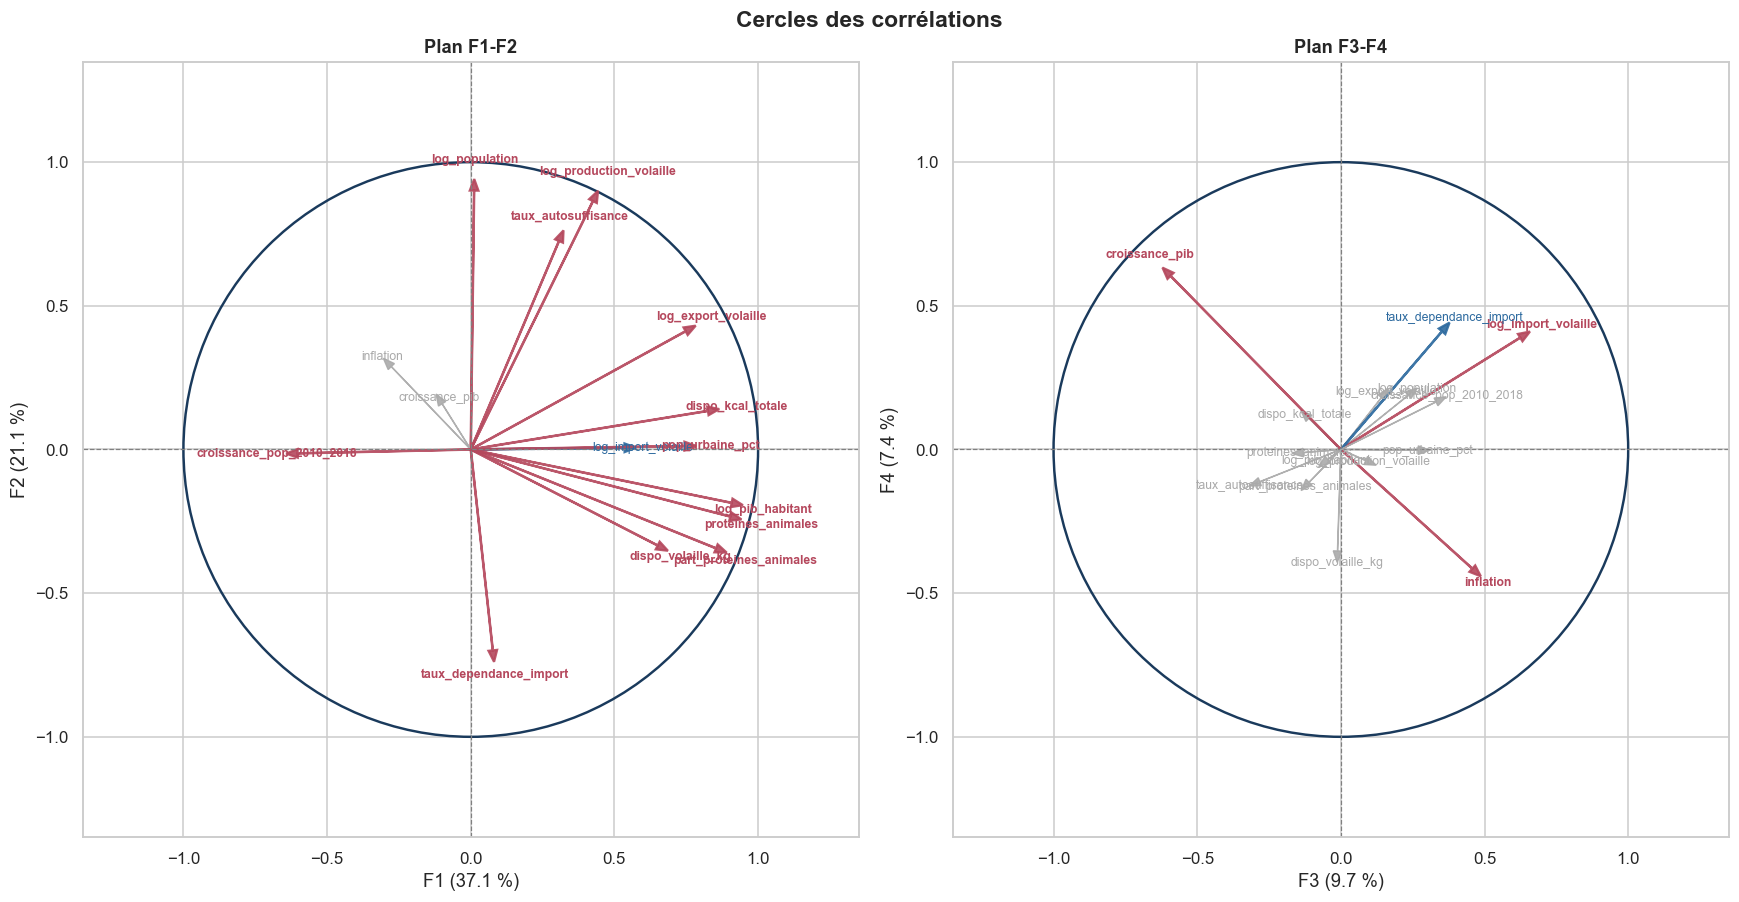

Code couleur : rouge = variable bien représentée (>0,6) | bleu = correcte (>0,4)
               gris  = mal représentée sur ce plan, à ne pas interpréter


In [135]:
# =============================================================================
# 4. CERCLE DES CORRÉLATIONS
# =============================================================================

# Coordonnées des variables = corrélation entre variable et composante
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(loadings[:, :N_AXES],
                           columns=[f"F{i+1}" for i in range(N_AXES)], index=VARS)

def cercle_correlations(axe_x, axe_y, ax):
    ax.add_artist(plt.Circle((0, 0), 1, fill=False, color="#1a3a5c", lw=1.6))
    ax.axhline(0, color="grey", lw=.8, ls="--")
    ax.axvline(0, color="grey", lw=.8, ls="--")
    for i, var in enumerate(VARS):
        x, y = loadings[i, axe_x], loadings[i, axe_y]
        qualite = np.sqrt(x**2 + y**2)
        couleur = "#b5485d" if qualite > .6 else ("#2d6a9f" if qualite > .4 else "#aaaaaa")
        ax.arrow(0, 0, x, y, head_width=.03, head_length=.04,
                 color=couleur, lw=1.5 if qualite > .4 else .9, alpha=.9)
        ax.text(x * 1.12, y * 1.12, var, fontsize=8, ha="center", va="center",
                color=couleur, fontweight="bold" if qualite > .6 else "normal")
    ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35)
    ax.set_xlabel(f"F{axe_x+1} ({var_ratio[axe_x]:.1f} %)")
    ax.set_ylabel(f"F{axe_y+1} ({var_ratio[axe_y]:.1f} %)")
    ax.set_title(f"Plan F{axe_x+1}-F{axe_y+1}", fontsize=12)
    ax.set_aspect("equal")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
cercle_correlations(0, 1, axes[0])
cercle_correlations(2, 3, axes[1])
fig.suptitle("Cercles des corrélations", fontsize=15, fontweight="bold", y=.99)
plt.tight_layout()
plt.show()

print("Code couleur : rouge = variable bien représentée (>0,6) | bleu = correcte (>0,4)")
print("               gris  = mal représentée sur ce plan, à ne pas interpréter")


In [136]:
# --- 4.2 Tableau des corrélations variables / axes ---------------------------

titre("4.2  CORRÉLATIONS VARIABLES - AXES FACTORIELS")
tab = loadings_df.round(3).copy()
tab["qualité_F1F2"] = np.sqrt(loadings_df["F1"]**2 + loadings_df["F2"]**2).round(3)
display(tab.sort_values("F1", ascending=False)
          .style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1,
                                     subset=[f"F{i+1}" for i in range(N_AXES)]))


4.2  CORRÉLATIONS VARIABLES - AXES FACTORIELS


,F1,F2,F3,F4,qualité_F1F2
log_pib_habitant,0.908000,-0.186000,-0.046000,-0.035000,0.927000
proteines_animales,0.903000,-0.233000,-0.131000,-0.011000,0.933000
part_proteines_animales,0.854000,-0.344000,-0.111000,-0.114000,0.920000
dispo_kcal_totale,0.825000,0.134000,-0.111000,0.108000,0.836000
log_export_volaille,0.748000,0.412000,0.141000,0.181000,0.854000
pop_urbaine_pct,0.744000,0.012000,0.269000,-0.002000,0.744000
dispo_volaille_kg,0.651000,-0.334000,-0.011000,-0.353000,0.731000
log_import_volaille,0.535000,0.006000,0.624000,0.389000,0.535000
log_production_volaille,0.425000,0.864000,0.086000,-0.039000,0.963000
taux_autosuffisance,0.307000,0.726000,-0.282000,-0.112000,0.788000


---
## 5. ACP — projection des individus

Chaque pays est maintenant positionné dans le nouvel espace factoriel.
Deux pays proches sur le graphique ont des **profils similaires** sur les variables retenues.


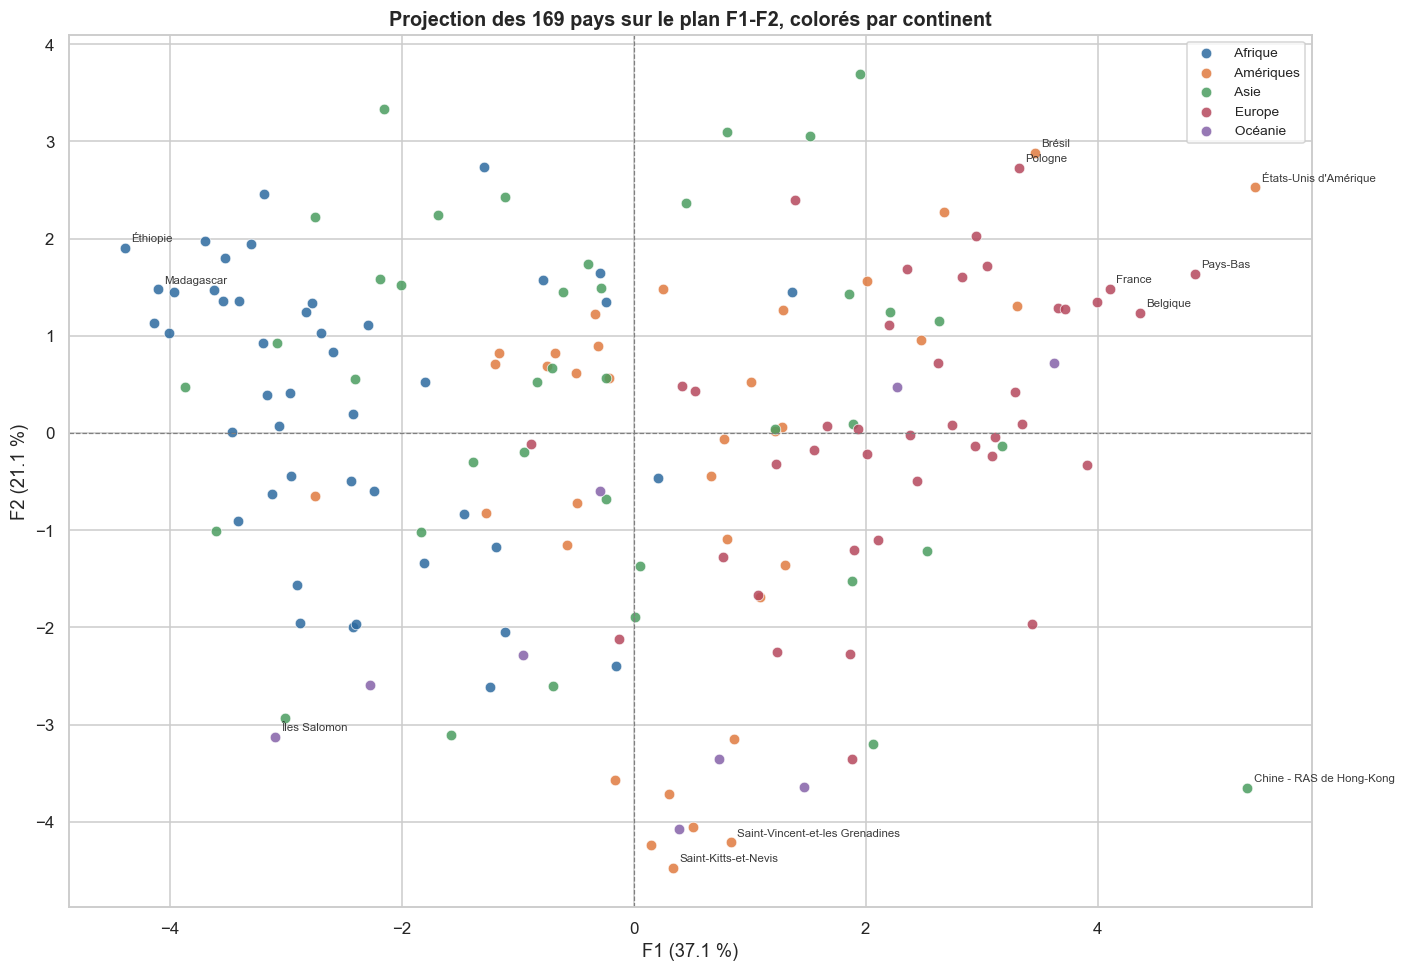

In [137]:
# =============================================================================
# 5. PROJECTION DES INDIVIDUS
# =============================================================================

def projeter(axe_x, axe_y, couleurs=None, titre_g="", legende="", ax=None,
             annoter=12, palette=None):
    seul = ax is None
    if seul:
        fig, ax = plt.subplots(figsize=(13, 9))
    if couleurs is None:
        ax.scatter(coords[:, axe_x], coords[:, axe_y], s=45, alpha=.75, color="#2d6a9f")
    else:
        modalites = pd.Series(couleurs).unique()
        pal = palette or PALETTE
        for i, m in enumerate(sorted(modalites, key=str)):
            msk = np.array(couleurs) == m
            ax.scatter(coords[msk, axe_x], coords[msk, axe_y], s=48, alpha=.85,
                       color=pal[i % len(pal)], label=f"{legende} {m}", edgecolor="white",
                       linewidth=.5)
        ax.legend(fontsize=9, loc="best")
    ax.axhline(0, color="grey", lw=.8, ls="--")
    ax.axvline(0, color="grey", lw=.8, ls="--")

    # On annote les pays les plus éloignés du centre : ce sont les plus caractéristiques
    dist = np.sqrt(coords[:, axe_x]**2 + coords[:, axe_y]**2)
    for i in np.argsort(dist)[-annoter:]:
        ax.annotate(PAYS[i], (coords[i, axe_x], coords[i, axe_y]),
                    fontsize=7.5, alpha=.9, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel(f"F{axe_x+1} ({var_ratio[axe_x]:.1f} %)")
    ax.set_ylabel(f"F{axe_y+1} ({var_ratio[axe_y]:.1f} %)")
    ax.set_title(titre_g or f"Projection des pays — plan F{axe_x+1}-F{axe_y+1}")
    if seul:
        plt.tight_layout(); plt.show()

projeter(0, 1, couleurs=df["continent"].tolist(), legende="",
         titre_g="Projection des 169 pays sur le plan F1-F2, colorés par continent")


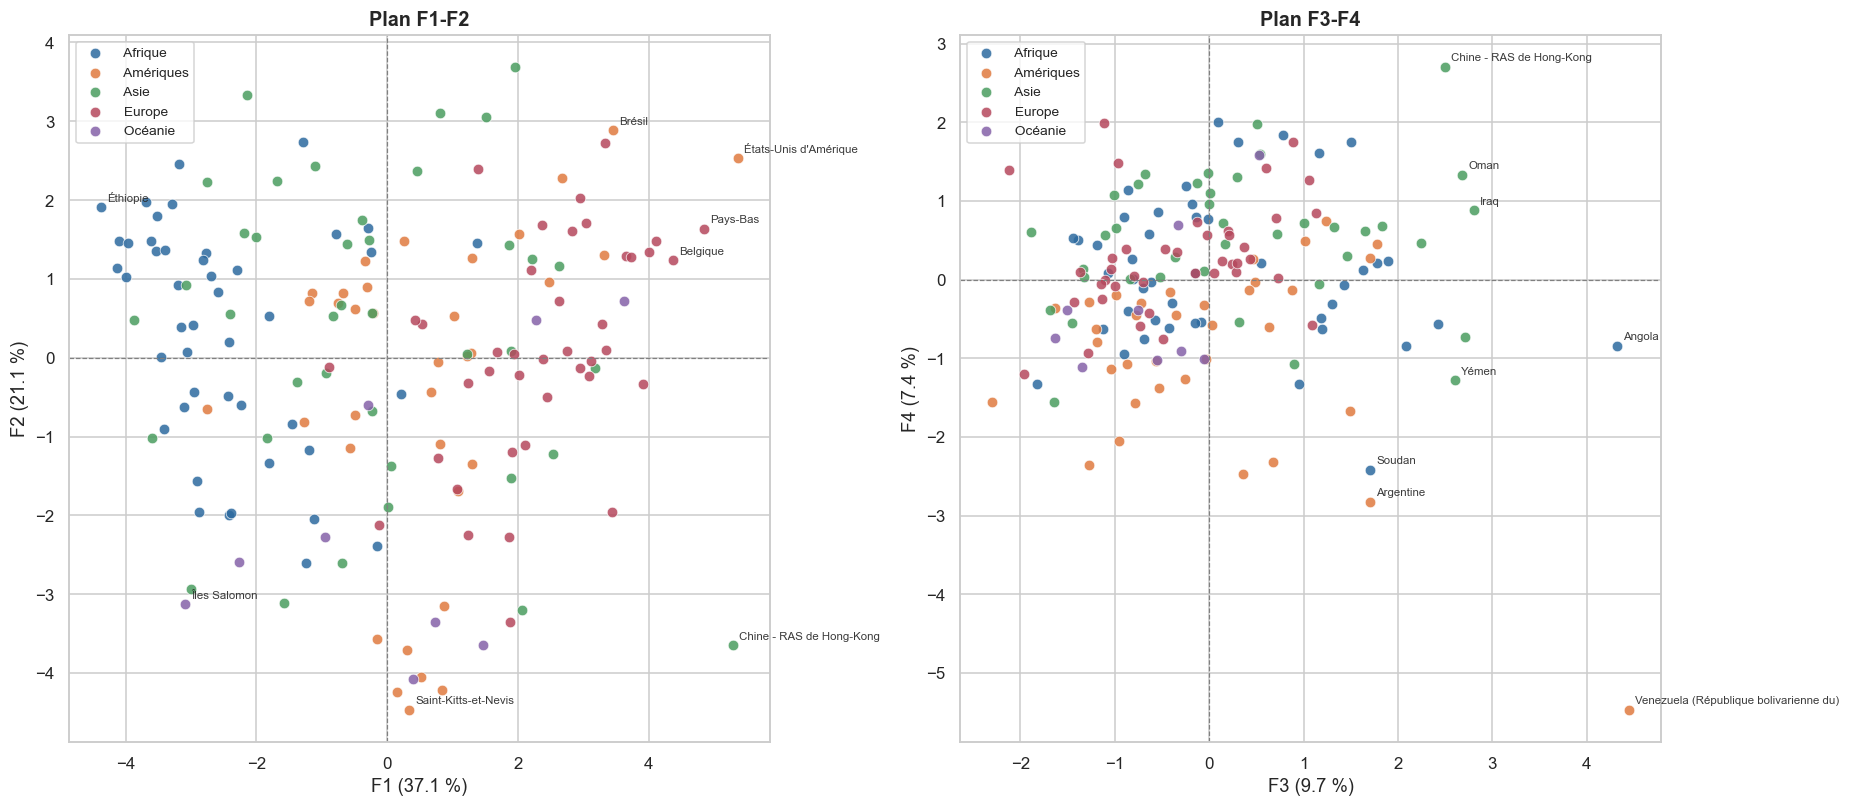

In [138]:
# --- 5.2 Plan F3-F4 -----------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
projeter(0, 1, couleurs=df["continent"].tolist(), ax=axes[0],
         titre_g="Plan F1-F2", annoter=8)
projeter(2, 3, couleurs=df["continent"].tolist(), ax=axes[1],
         titre_g="Plan F3-F4", annoter=8)
plt.tight_layout()
plt.show()


---
## 6. ACP — qualité de représentation et contributions

Deux indicateurs complètent l'analyse :

- le **cos²** mesure la **qualité de représentation** d'un pays sur un axe.
  Proche de 1 : le pays est bien décrit par cet axe. Proche de 0 : sa position sur le
  graphique n'est pas interprétable.
- la **contribution** mesure le poids d'un pays dans la construction de l'axe.
  Une contribution très élevée signale un individu qui « tire » l'axe à lui seul.


In [139]:
# =============================================================================
# 6. QUALITÉ DE REPRÉSENTATION ET CONTRIBUTIONS
# =============================================================================

# cos² : part de la distance au centre expliquée par chaque axe
d2 = (coords ** 2).sum(axis=1)
cos2 = (coords ** 2) / d2[:, None]
cos2_df = pd.DataFrame(cos2[:, :N_AXES],
                       columns=[f"cos2_F{i+1}" for i in range(N_AXES)], index=PAYS)
cos2_df["cos2_F1F2"] = cos2_df["cos2_F1"] + cos2_df["cos2_F2"]

# contributions : poids de chaque individu dans l'inertie de l'axe
contrib = (coords ** 2) / (coords ** 2).sum(axis=0)
contrib_df = pd.DataFrame(contrib[:, :N_AXES] * 100,
                          columns=[f"contrib_F{i+1}_%" for i in range(N_AXES)], index=PAYS)

titre("6.1  PAYS LES MIEUX REPRÉSENTÉS SUR LE PLAN F1-F2")
display(cos2_df.nlargest(10, "cos2_F1F2").round(3))

titre("6.2  PAYS LES MOINS BIEN REPRÉSENTÉS (à interpréter avec prudence)")
display(cos2_df.nsmallest(10, "cos2_F1F2").round(3))

titre("6.3  PAYS CONTRIBUANT LE PLUS À LA CONSTRUCTION DES AXES")
display(contrib_df.nlargest(10, "contrib_F1_%").round(2))
print(f"Contribution moyenne attendue si tous les pays pesaient pareil : "
      f"{100/len(PAYS):.2f} %")


6.1  PAYS LES MIEUX REPRÉSENTÉS SUR LE PLAN F1-F2


,cos2_F1,cos2_F2,cos2_F3,cos2_F4,cos2_F1F2
Danemark,0.94,0.01,0.00,0.02,0.94
Espagne,0.83,0.10,0.00,0.00,0.93
République-Unie de Tanzanie,0.73,0.19,0.02,0.02,0.92
Rwanda,0.86,0.06,0.04,0.01,0.92
Madagascar,0.81,0.10,0.01,0.02,0.92
France,0.79,0.10,0.02,0.03,0.89
Polynésie française,0.12,0.77,0.03,0.01,0.89
Ouganda,0.78,0.10,0.01,0.00,0.89
Italie,0.67,0.21,0.00,0.00,0.88
États-Unis d'Amérique,0.72,0.16,0.01,0.00,0.88


6.2  PAYS LES MOINS BIEN REPRÉSENTÉS (à interpréter avec prudence)


,cos2_F1,cos2_F2,cos2_F3,cos2_F4,cos2_F1F2
Venezuela (République bolivarienne du),0.00,0.03,0.35,0.53,0.03
Maurice,0.01,0.03,0.49,0.26,0.04
Jordanie,0.01,0.03,0.22,0.01,0.04
Bosnie-Herzégovine,0.04,0.03,0.30,0.01,0.07
Guyana,0.02,0.05,0.54,0.24,0.08
Liban,0.07,0.03,0.13,0.00,0.10
Fidji,0.02,0.08,0.57,0.12,0.10
Jamaïque,0.08,0.04,0.01,0.30,0.12
Géorgie,0.01,0.11,0.01,0.12,0.12
El Salvador,0.01,0.11,0.04,0.07,0.12


6.3  PAYS CONTRIBUANT LE PLUS À LA CONSTRUCTION DES AXES


,contrib_F1_%,contrib_F2_%,contrib_F3_%,contrib_F4_%
États-Unis d'Amérique,3.07,1.20,0.07,0.01
Chine - RAS de Hong-Kong,2.99,2.50,2.56,3.92
Pays-Bas,2.50,0.50,0.15,1.07
Éthiopie,2.05,0.68,0.33,0.34
Belgique,2.04,0.29,0.32,1.63
Rwanda,1.83,0.24,0.30,0.08
France,1.80,0.41,0.20,0.33
Madagascar,1.79,0.41,0.07,0.20
Niger,1.71,0.20,0.12,0.39
Allemagne,1.71,0.34,0.46,0.86


Contribution moyenne attendue si tous les pays pesaient pareil : 0.60 %


---
## 7. Interprétation des axes factoriels

**C'est l'étape la plus importante de l'ACP.** Produire les graphiques ne suffit pas :
il faut nommer ce que chaque axe représente, en langage métier.


In [140]:
# =============================================================================
# 7. INTERPRÉTATION DES AXES
# =============================================================================

titre("VARIABLES STRUCTURANTES DE CHAQUE AXE (|corrélation| > 0,4)")

for i in range(N_AXES):
    axe = f"F{i+1}"
    s = loadings_df[axe].sort_values(ascending=False)
    forts = s[s.abs() > 0.4]
    print(f"\n{'-'*78}")
    print(f"{axe}  —  {var_ratio[i]:.1f} % de la variance totale")
    print(f"{'-'*78}")
    print("  Côté POSITIF :")
    for v, val in forts[forts > 0].items():
        print(f"      {val:+.2f}   {v}")
    print("  Côté NÉGATIF :")
    for v, val in forts[forts < 0].sort_values().items():
        print(f"      {val:+.2f}   {v}")
    if forts.empty:
        print("      (aucune variable fortement corrélée à cet axe)")


VARIABLES STRUCTURANTES DE CHAQUE AXE (|corrélation| > 0,4)

------------------------------------------------------------------------------
F1  —  37.1 % de la variance totale
------------------------------------------------------------------------------
  Côté POSITIF :
      +0.91   log_pib_habitant
      +0.90   proteines_animales
      +0.85   part_proteines_animales
      +0.83   dispo_kcal_totale
      +0.75   log_export_volaille
      +0.74   pop_urbaine_pct
      +0.65   dispo_volaille_kg
      +0.54   log_import_volaille
      +0.43   log_production_volaille
  Côté NÉGATIF :
      -0.60   croissance_pop_2010_2018

------------------------------------------------------------------------------
F2  —  21.1 % de la variance totale
------------------------------------------------------------------------------
  Côté POSITIF :
      +0.90   log_population
      +0.86   log_production_volaille
      +0.73   taux_autosuffisance
      +0.41   log_export_volaille
  Côté NÉGATIF :
      

### Lecture des axes

**Axe F1 — le niveau de développement du marché** *(37,1 % de la variance)*

Le côté positif rassemble le PIB par habitant (+0,91), les protéines animales (+0,90),
leur part dans le régime (+0,86), l'apport calorique total (+0,82), l'urbanisation (+0,74)
et la consommation de volaille (+0,65). Il s'oppose à la croissance démographique (−0,59).

F1 oppose donc **les pays riches, urbanisés, au régime alimentaire riche en protéines
animales** aux **pays pauvres à forte croissance démographique et régime majoritairement
végétal**. C'est l'axe de la transition alimentaire : à mesure qu'un pays s'enrichit et
s'urbanise, il mange plus de viande et croît moins vite démographiquement.

*Pour La poule qui chante* : le côté positif de F1 rassemble les **marchés solvables**,
ceux qui peuvent payer un poulet bio. Le côté négatif rassemble des marchés de volume
futur, mais pas de valeur aujourd'hui.

**Axe F2 — l'autonomie productive** *(21,1 % de la variance)*

Le côté positif combine la population (+0,90), la production de volaille (+0,87),
le taux d'autosuffisance (+0,73) et les exportations (+0,41). Il s'oppose frontalement
au taux de dépendance aux importations (−0,70).

F2 oppose **les grands pays producteurs, autosuffisants voire exportateurs** aux
**petits pays structurellement dépendants des importations**. C'est l'axe
**producteur ↔ importateur**.

*Pour La poule qui chante* : c'est **l'axe commercial décisif**. Le côté négatif de F2
est celui des clients — des pays qui achètent déjà leur volaille à l'étranger.
Le côté positif est celui des concurrents.

**Axes F3 et F4 — le climat macro-économique** *(9,7 % et 7,4 %)*

Les deux axes mobilisent les mêmes variables avec des signes inversés, et séparent
deux situations économiques distinctes :

- **F3** associe importations (+0,62) et inflation (+0,47) contre croissance du PIB (−0,59) :
  c'est le profil du pays **importateur sous tension**, qui subit la hausse des prix
  sans dynamisme économique.
- **F4** associe croissance du PIB (+0,60) et dépendance aux importations (+0,41)
  contre inflation (−0,41) : c'est le profil du pays **importateur en croissance saine**.

*Pour La poule qui chante* : à profil équivalent sur F1-F2, un pays du côté positif de F4
est un client plus sûr qu'un pays du côté positif de F3. C'est un critère de départage
du risque commercial.
### Réponse aux questions de soutenance

> **« En quoi est-ce intéressant d'utiliser une ACP ? »**
>
> Trois raisons. D'abord, elle **réduit la dimension** : 15 variables corrélées deviennent
> 4 axes indépendants, ce qui accélère et stabilise le clustering. Ensuite, elle **supprime
> la redondance** : plusieurs variables mesuraient partiellement la même chose, l'ACP les
> fusionne. Enfin, elle **rend l'analyse visualisable** : on ne peut pas dessiner un espace
> à 15 dimensions, on peut dessiner un plan.

> **« Comment as-tu choisi le nombre d'axes ? »**
>
> Par convergence de trois critères — Kaiser, coude de l'éboulis, et seuil de variance
> cumulée — et non par un seul, afin que la décision ne dépende pas d'un critère isolé.


---
## 8. Classification ascendante hiérarchique (CAH)

La CAH part de 169 groupes d'un pays chacun, puis **fusionne à chaque étape les deux groupes
les plus proches**, jusqu'à n'en avoir qu'un. Le **dendrogramme** représente cet historique.

**Méthode de Ward** : à chaque fusion, on choisit celle qui augmente le moins la variance
interne des groupes. C'est la méthode la plus adaptée à des variables quantitatives
centrées-réduites, et elle produit des groupes de taille équilibrée.

Le nombre de clusters se lit sur le dendrogramme : on **coupe l'arbre** à la hauteur où les
branches sont les plus longues, c'est-à-dire là où fusionner coûterait le plus cher.


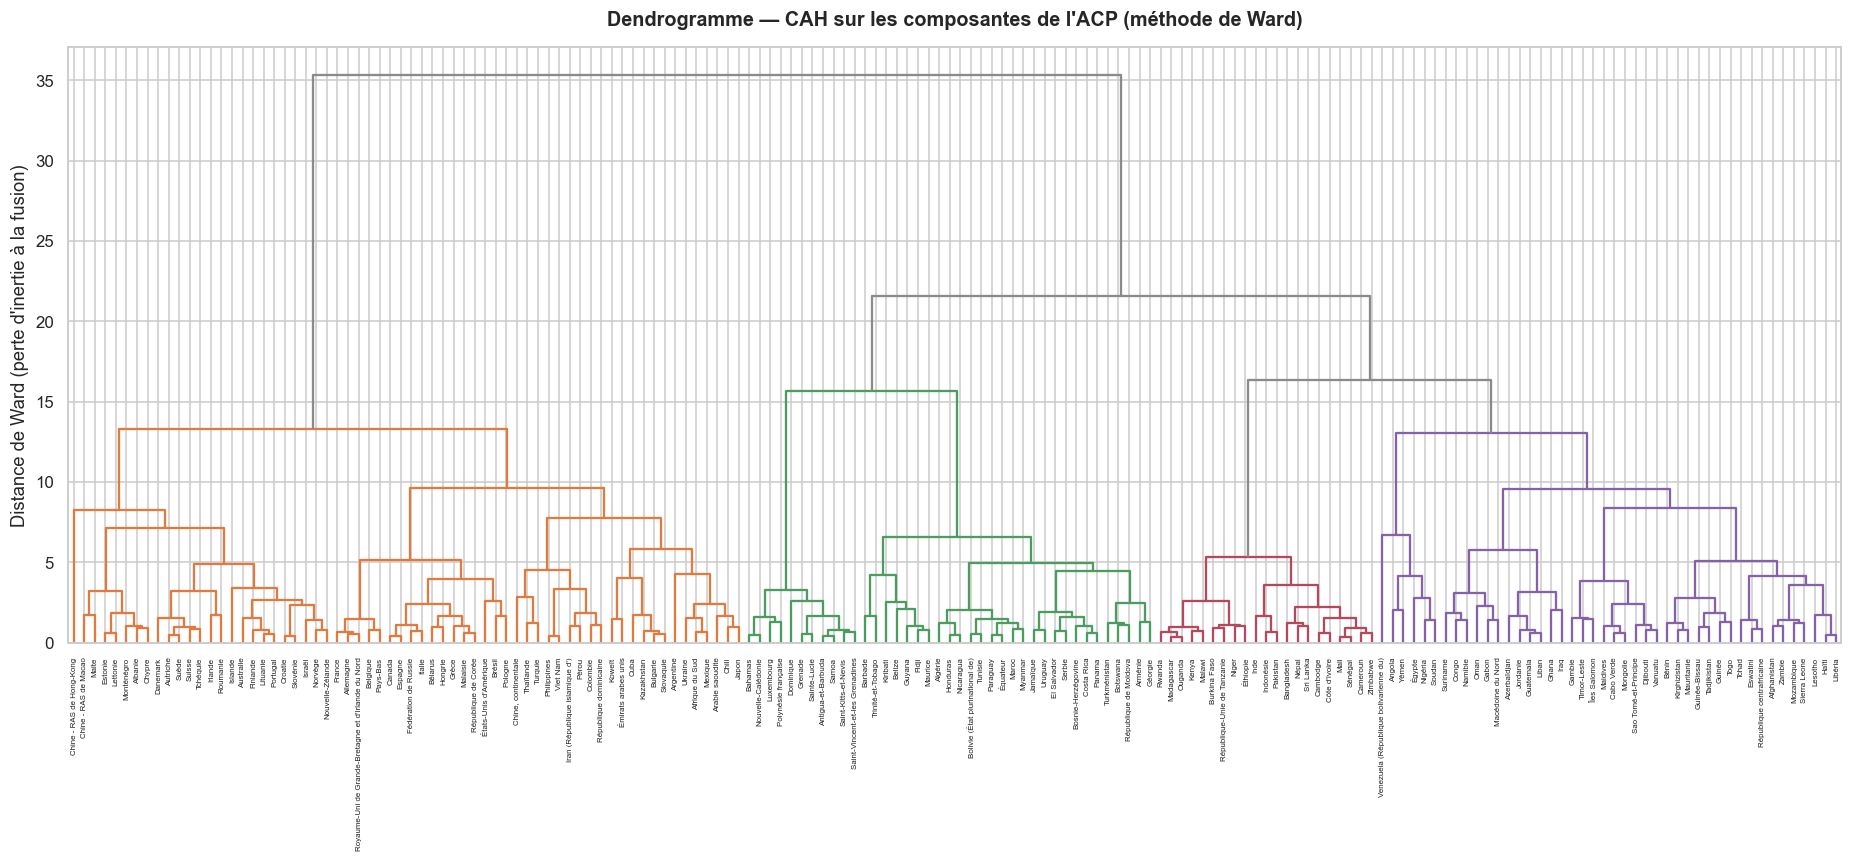

In [141]:
# =============================================================================
# 8. CLASSIFICATION ASCENDANTE HIÉRARCHIQUE
# =============================================================================

Z = linkage(coords_ret, method="ward")

fig, ax = plt.subplots(figsize=(17, 8))
dendrogram(Z, labels=PAYS, leaf_rotation=90, leaf_font_size=5.2,
           color_threshold=Z[-3, 2], ax=ax,
           above_threshold_color="#8a8a8a")
ax.set_title("Dendrogramme — CAH sur les composantes de l'ACP (méthode de Ward)", pad=14)
ax.set_ylabel("Distance de Ward (perte d'inertie à la fusion)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()


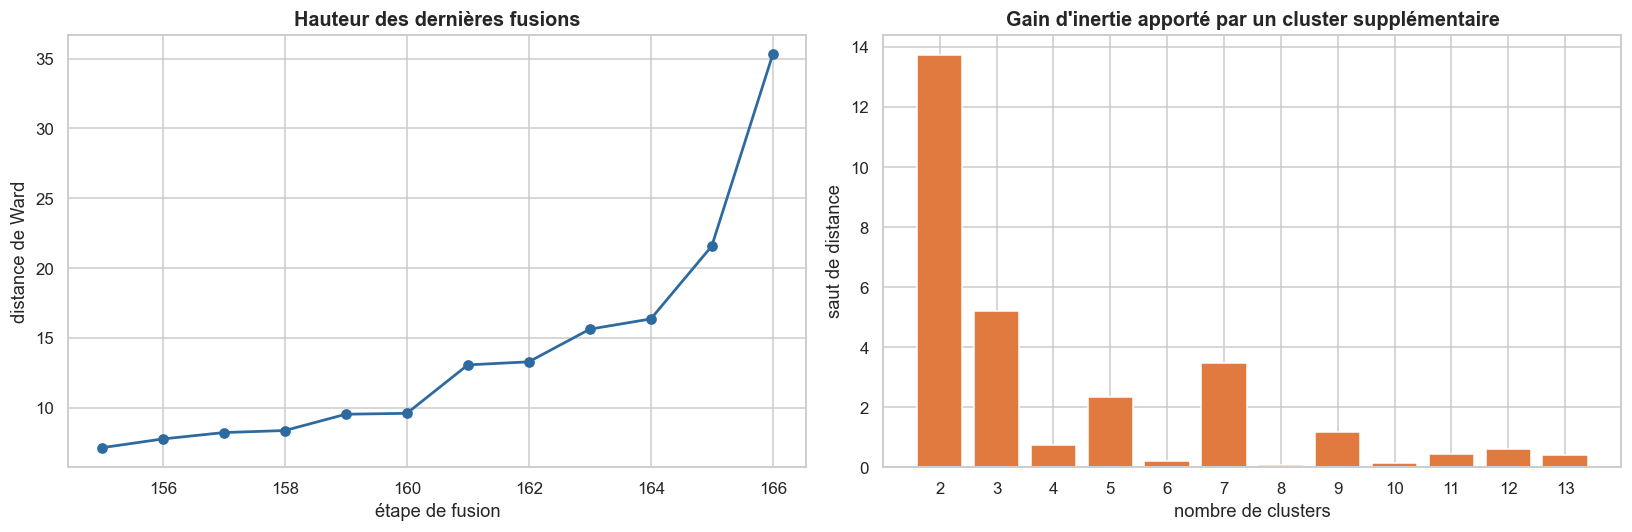

Lecture : un saut important signifie que passer à ce nombre de clusters
évite une fusion coûteuse. Les plus grands sauts indiquent les découpages naturels.


In [142]:
# --- 8.2 Où couper l'arbre ? --------------------------------------------------

distances = Z[:, 2]
sauts = np.diff(distances)
derniers = 12

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(range(len(distances) - derniers, len(distances)),
             distances[-derniers:], "o-", color="#2d6a9f", lw=1.8)
axes[0].set_title("Hauteur des dernières fusions")
axes[0].set_xlabel("étape de fusion")
axes[0].set_ylabel("distance de Ward")

k_range = np.arange(2, derniers + 2)
gains = sauts[-derniers:][::-1]
axes[1].bar(k_range[:len(gains)], gains, color="#e07a3f", edgecolor="white")
axes[1].set_title("Gain d'inertie apporté par un cluster supplémentaire")
axes[1].set_xlabel("nombre de clusters")
axes[1].set_ylabel("saut de distance")
axes[1].set_xticks(k_range[:len(gains)])
plt.tight_layout()
plt.show()

print("Lecture : un saut important signifie que passer à ce nombre de clusters")
print("évite une fusion coûteuse. Les plus grands sauts indiquent les découpages naturels.")


In [143]:
# --- 8.3 Essais sur plusieurs valeurs de k ------------------------------------

titre("8.3  ESSAIS DE DÉCOUPAGE — CAH")

resultats_cah = []
for k in range(2, 9):
    lab = fcluster(Z, k, criterion="maxclust")
    sil = silhouette_score(coords_ret, lab)
    tailles = pd.Series(lab).value_counts().sort_index().tolist()
    resultats_cah.append({
        "k": k, "silhouette": round(sil, 3),
        "taille_min": min(tailles), "taille_max": max(tailles),
        "répartition": tailles,
    })

display(pd.DataFrame(resultats_cah))
print("\nLe coefficient de silhouette mesure la qualité de la partition :")
print("  proche de 1  = clusters denses et bien séparés")
print("  proche de 0  = clusters qui se chevauchent")
print("  négatif      = individus mal classés")
print("\nOn écarte les partitions produisant des clusters d'un ou deux pays :")
print("statistiquement corrects, mais inutilisables pour une décision commerciale.")


8.3  ESSAIS DE DÉCOUPAGE — CAH


,k,silhouette,taille_min,taille_max,répartition
0,2,0.29,64,104,"[64, 104]"
1,3,0.23,39,65,"[64, 39, 65]"
2,4,0.21,21,64,"[64, 39, 21, 44]"
3,5,0.21,11,64,"[64, 11, 28, 21, 44]"
4,6,0.20,11,44,"[25, 39, 11, 28, 21, 44]"
5,7,0.22,6,39,"[25, 39, 11, 28, 21, 6, 38]"
6,8,0.22,6,38,"[25, 17, 22, 11, 28, 21, 6, 38]"



Le coefficient de silhouette mesure la qualité de la partition :
  proche de 1  = clusters denses et bien séparés
  proche de 0  = clusters qui se chevauchent
  négatif      = individus mal classés

On écarte les partitions produisant des clusters d'un ou deux pays :
statistiquement corrects, mais inutilisables pour une décision commerciale.


In [144]:
# --- 8.4 Partition retenue -----------------------------------------------------

K = 4          # décision argumentée

df["cluster_cah"] = fcluster(Z, K, criterion="maxclust")

titre(f"8.4  PARTITION CAH RETENUE : K = {K}")
print(f"Silhouette : {silhouette_score(coords_ret, df['cluster_cah']):.3f}\n")
display(df["cluster_cah"].value_counts().sort_index()
          .rename("nb_pays").to_frame()
          .assign(**{"%": lambda t: (t["nb_pays"]/len(df)*100).round(1)}))


8.4  PARTITION CAH RETENUE : K = 4
Silhouette : 0.211



,nb_pays,%
cluster_cah,,
1,64,38.10
2,39,23.20
3,21,12.50
4,44,26.20


---
## 9. K-means — recherche du nombre optimal de clusters

Le k-means fonctionne différemment : on fixe **à l'avance** le nombre de clusters `k`,
l'algorithme place `k` centres au hasard, affecte chaque pays au centre le plus proche,
recalcule les centres, et recommence jusqu'à stabilisation.

Deux méthodes convergentes pour choisir `k` :

- **la méthode du coude** — on trace l'inertie intra-cluster en fonction de `k`.
  Elle décroît toujours, mais on cherche le point où elle cesse de décroître fortement.
- **le coefficient de silhouette** — on cherche le maximum.

> `random_state=42` fixe la graine aléatoire : les résultats sont **reproductibles à
> l'identique**. Sans cela, deux exécutions donneraient des clusters différents, ce qui est
> rédhibitoire pour un livrable.


In [145]:
# =============================================================================
# 9. K-MEANS
# =============================================================================

titre("9.1  ESSAIS SUR PLUSIEURS VALEURS DE K")

inerties, silhouettes, resultats_km = [], [], []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    lab = km.fit_predict(coords_ret)
    sil = silhouette_score(coords_ret, lab)
    inerties.append(km.inertia_)
    silhouettes.append(sil)
    tailles = pd.Series(lab).value_counts().sort_index().tolist()
    resultats_km.append({"k": k, "inertie": round(km.inertia_, 1),
                         "silhouette": round(sil, 3),
                         "taille_min": min(tailles), "répartition": tailles})

display(pd.DataFrame(resultats_km))


9.1  ESSAIS SUR PLUSIEURS VALEURS DE K


,k,inertie,silhouette,taille_min,répartition
0,2,"1,220.50",0.32,82,"[82, 86]"
1,3,915.00,0.32,42,"[42, 60, 66]"
2,4,788.20,0.29,28,"[53, 28, 56, 31]"
3,5,678.10,0.28,23,"[50, 27, 32, 23, 36]"
4,6,613.70,0.26,17,"[29, 24, 36, 30, 32, 17]"
5,7,543.80,0.27,6,"[16, 32, 6, 28, 28, 29, 29]"
6,8,505.50,0.27,6,"[6, 27, 26, 31, 16, 25, 8, 29]"
7,9,473.30,0.26,5,"[19, 27, 25, 29, 19, 18, 11, 5, 15]"
8,10,454.00,0.25,8,"[23, 25, 10, 8, 26, 11, 19, 15, 8, 23]"


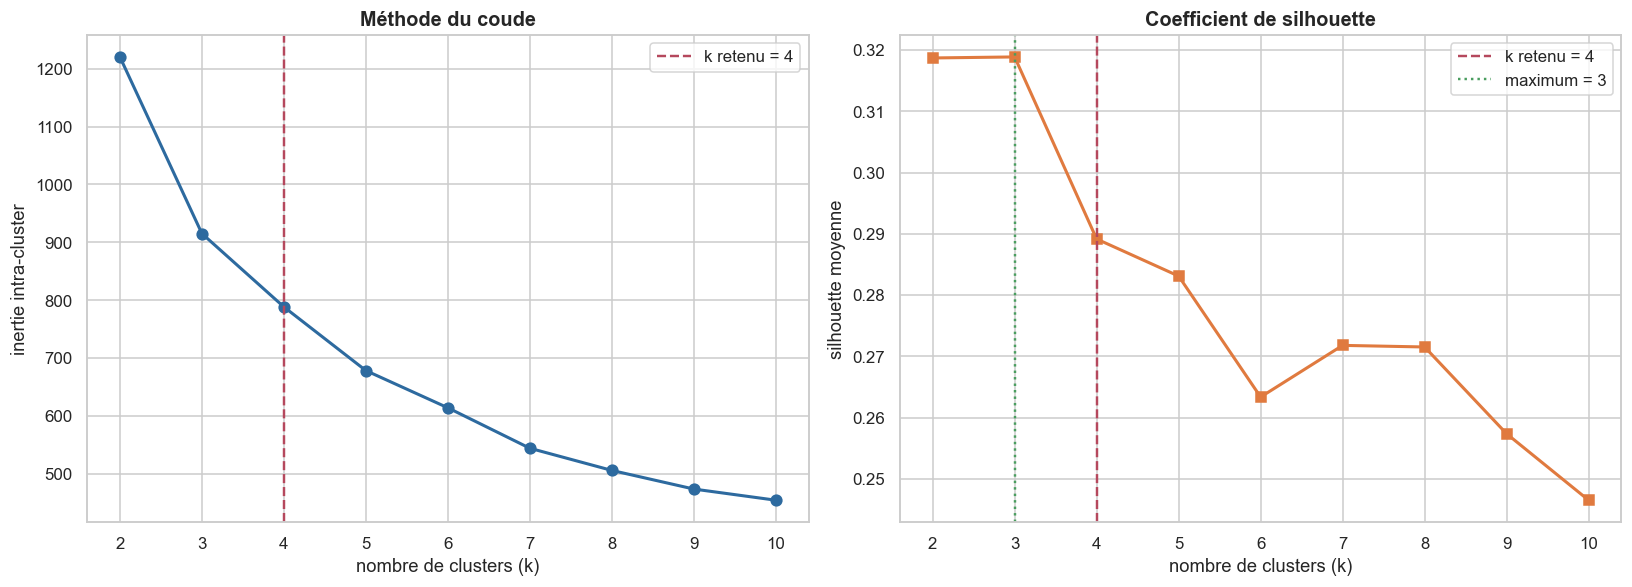

Silhouette maximale  : k = 3 (0.319)
Nombre de clusters retenu : k = 4

Justification du choix retenu :
  • le coude apparaît autour de k = 3-4 ;
  • la silhouette y reste élevée ;
  • surtout, 4 groupes sont exploitables commercialement : c'est un nombre
    de segments qu'un COMEX peut comprendre et sur lequel il peut arbitrer.
  Un critère purement statistique n'est pas suffisant : la lisibilité métier compte.


In [146]:
# --- 9.2 Coude et silhouette --------------------------------------------------

ks = list(range(2, 11))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(ks, inerties, "o-", color="#2d6a9f", lw=2, ms=7)
axes[0].axvline(K, color="#b5485d", ls="--", lw=1.6, label=f"k retenu = {K}")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("nombre de clusters (k)")
axes[0].set_ylabel("inertie intra-cluster")
axes[0].set_xticks(ks); axes[0].legend()

axes[1].plot(ks, silhouettes, "s-", color="#e07a3f", lw=2, ms=7)
axes[1].axvline(K, color="#b5485d", ls="--", lw=1.6, label=f"k retenu = {K}")
best = ks[int(np.argmax(silhouettes))]
axes[1].axvline(best, color="#4a9d5f", ls=":", lw=1.6, label=f"maximum = {best}")
axes[1].set_title("Coefficient de silhouette")
axes[1].set_xlabel("nombre de clusters (k)")
axes[1].set_ylabel("silhouette moyenne")
axes[1].set_xticks(ks); axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Silhouette maximale  : k = {best} ({max(silhouettes):.3f})")
print(f"Nombre de clusters retenu : k = {K}")
print()
print("Justification du choix retenu :")
print("  • le coude apparaît autour de k = 3-4 ;")
print("  • la silhouette y reste élevée ;")
print("  • surtout, 4 groupes sont exploitables commercialement : c'est un nombre")
print("    de segments qu'un COMEX peut comprendre et sur lequel il peut arbitrer.")
print("  Un critère purement statistique n'est pas suffisant : la lisibilité métier compte.")


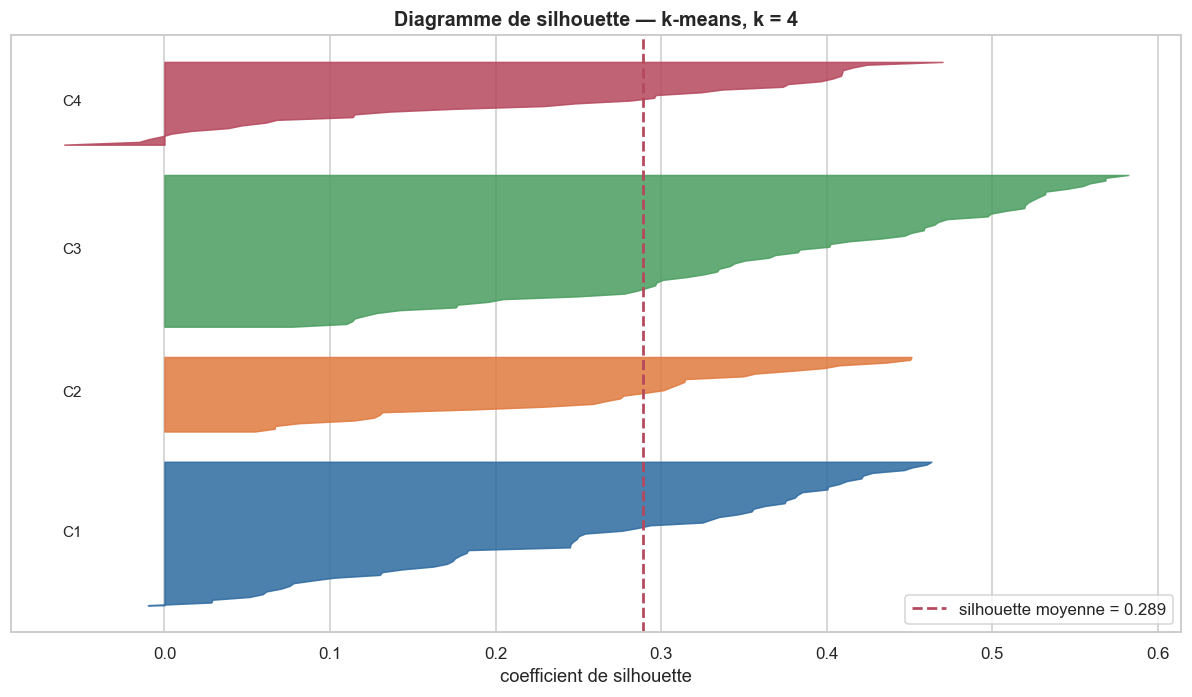

Pays au coefficient négatif (mal classés) : 5 sur 168


In [147]:
# --- 9.3 Partition k-means retenue et diagramme de silhouette ----------------

km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
df["cluster_kmeans"] = km.fit_predict(coords_ret) + 1     # numérotation à partir de 1

sil_vals = silhouette_samples(coords_ret, df["cluster_kmeans"])
sil_moy = sil_vals.mean()

fig, ax = plt.subplots(figsize=(11, 6.5))
y_bas = 10
for i, c in enumerate(sorted(df["cluster_kmeans"].unique())):
    vals = np.sort(sil_vals[df["cluster_kmeans"] == c])
    y_haut = y_bas + len(vals)
    ax.fill_betweenx(np.arange(y_bas, y_haut), 0, vals,
                     color=PALETTE[i % len(PALETTE)], alpha=.85)
    ax.text(-0.05, y_bas + len(vals) / 2, f"C{c}", ha="right", va="center", fontsize=10)
    y_bas = y_haut + 10
ax.axvline(sil_moy, color="#b5485d", ls="--", lw=1.8,
           label=f"silhouette moyenne = {sil_moy:.3f}")
ax.set_xlabel("coefficient de silhouette")
ax.set_ylabel("")
ax.set_yticks([])
ax.set_title(f"Diagramme de silhouette — k-means, k = {K}")
ax.legend()
plt.tight_layout()
plt.show()

mal_classes = (sil_vals < 0).sum()
print(f"Pays au coefficient négatif (mal classés) : {mal_classes} sur {len(df)}")


---
## 10. Comparaison des deux méthodes

Les deux algorithmes ne fonctionnent pas de la même façon : il est normal qu'ils ne donnent
pas exactement la même partition. Ce qui compte est de mesurer **à quel point ils convergent**.

L'**indice de Rand ajusté (ARI)** quantifie l'accord entre deux partitions :

| ARI | Interprétation |
|---|---|
| 1,00 | partitions identiques |
| > 0,75 | accord très fort |
| 0,50 – 0,75 | accord substantiel |
| ≈ 0 | accord équivalent au hasard |


In [148]:
# =============================================================================
# 10. COMPARAISON CAH / K-MEANS
# =============================================================================

ari = adjusted_rand_score(df["cluster_cah"], df["cluster_kmeans"])

titre("10.1  TABLE DE CONTINGENCE")
cont = pd.crosstab(df["cluster_cah"], df["cluster_kmeans"],
                   rownames=["CAH"], colnames=["K-means"], margins=True,
                   margins_name="Total")
display(cont)

print(f"\nIndice de Rand ajusté : {ari:.3f}")
accord = (cont.iloc[:-1, :-1].max(axis=1).sum() / len(df)) * 100
print(f"Taux d'accord (appariement optimal des étiquettes) : {accord:.1f} %")


10.1  TABLE DE CONTINGENCE


K-means,1,2,3,4,Total
CAH,,,,,
1,2,0,51,11,64
2,13,2,5,19,39
3,21,0,0,0,21
4,17,26,0,1,44
Total,53,28,56,31,168



Indice de Rand ajusté : 0.435
Taux d'accord (appariement optimal des étiquettes) : 69.6 %


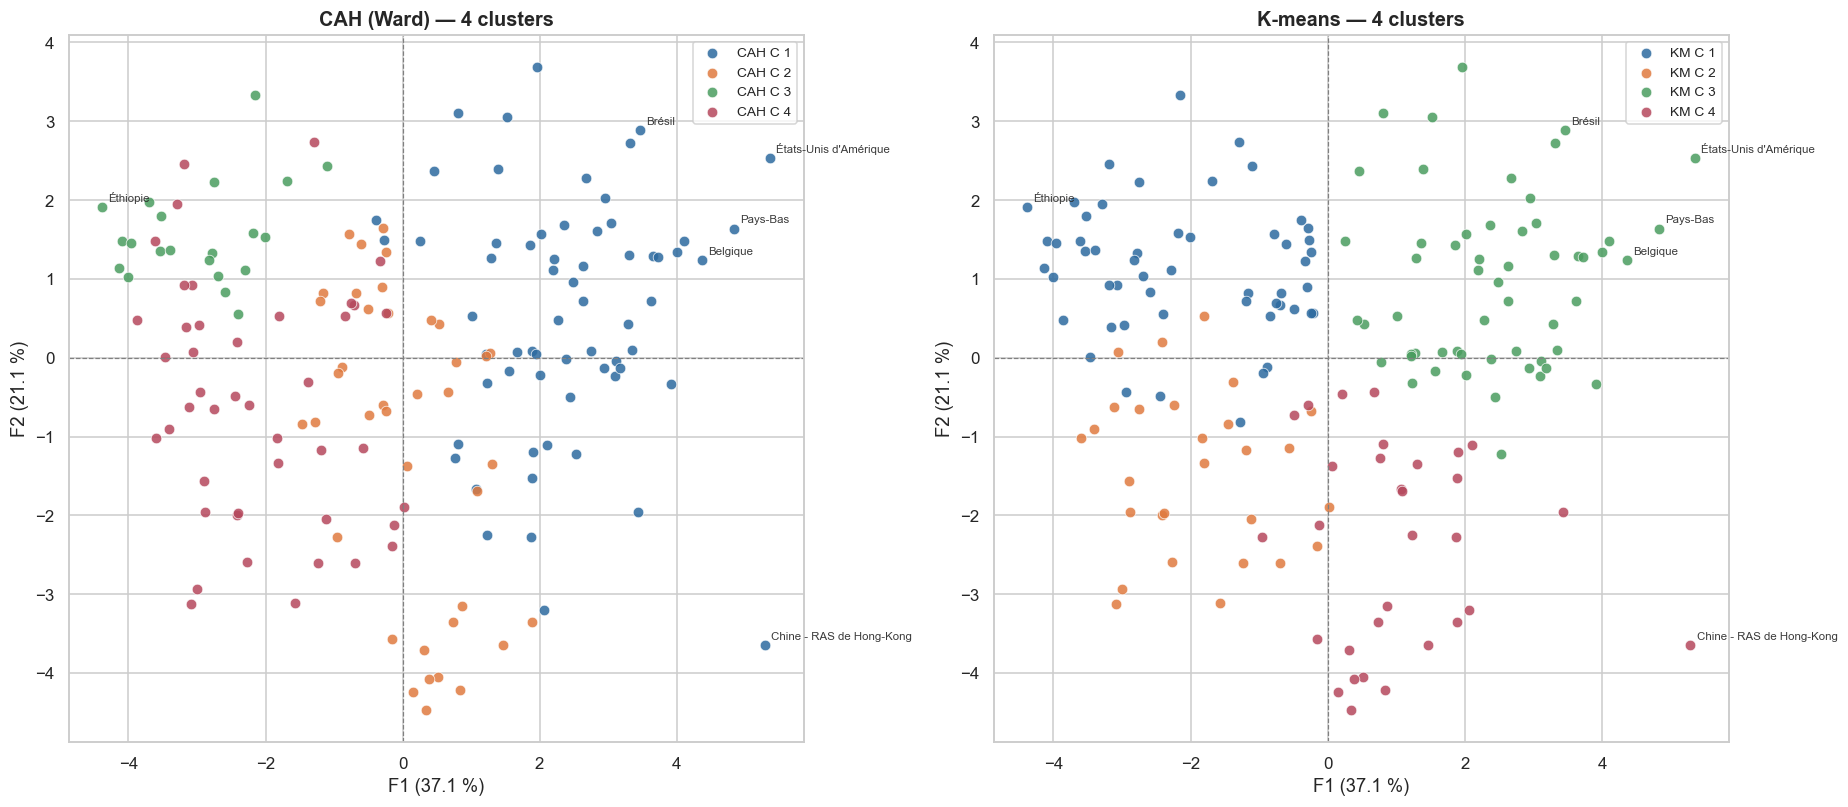

In [149]:
# --- 10.2 Visualisation côte à côte ------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
projeter(0, 1, couleurs=df["cluster_cah"].tolist(), legende="CAH C",
         titre_g=f"CAH (Ward) — {K} clusters", ax=axes[0], annoter=6)
projeter(0, 1, couleurs=df["cluster_kmeans"].tolist(), legende="KM C",
         titre_g=f"K-means — {K} clusters", ax=axes[1], annoter=6)
plt.tight_layout()
plt.show()


In [150]:
# --- 10.3 Les pays sur lesquels les deux méthodes divergent ------------------

# Appariement des étiquettes : à chaque cluster CAH on associe le cluster k-means dominant
corresp = cont.iloc[:-1, :-1].idxmax(axis=1).to_dict()
df["_cah_apparie"] = df["cluster_cah"].map(corresp)
divergents = df.loc[df["_cah_apparie"] != df["cluster_kmeans"],
                    ["pays", "continent", "cluster_cah", "_cah_apparie", "cluster_kmeans"]] \
               .rename(columns={"_cah_apparie": "cluster_kmeans_attendu"})

titre("10.3  PAYS CLASSÉS DIFFÉREMMENT PAR LES DEUX MÉTHODES")
print(f"{len(divergents)} pays sur {len(df)} ({len(divergents)/len(df)*100:.1f} %)\n")
display(divergents.reset_index(drop=True))
df = df.drop(columns="_cah_apparie")


10.3  PAYS CLASSÉS DIFFÉREMMENT PAR LES DEUX MÉTHODES
51 pays sur 168 (30.4 %)



,pays,continent,cluster_cah,cluster_kmeans_attendu,cluster_kmeans
0,Afghanistan,Asie,4,2,1
1,Albanie,Europe,1,3,4
2,Algérie,Afrique,2,4,1
3,Azerbaïdjan,Asie,4,2,1
4,Belize,Amériques,2,4,1
5,Bolivie (État plurinational de),Amériques,2,4,1
6,Bosnie-Herzégovine,Europe,2,4,3
7,Botswana,Afrique,2,4,2
8,Chine - RAS de Hong-Kong,Asie,1,3,4
9,Chine - RAS de Macao,Asie,1,3,4


> ### Réponse de soutenance — *« Les deux méthodes ont-elles donné les mêmes résultats ? »*
>
> Les partitions sont **largement convergentes mais pas identiques**, et c'est attendu :
>
> | | CAH | K-means |
> |---|---|---|
> | Principe | fusions successives, ascendant | optimisation itérative autour de centres |
> | Nombre de clusters | décidé **après** coup, en coupant l'arbre | fixé **avant** l'exécution |
> | Réversibilité | une fusion n'est jamais remise en cause | un pays peut changer de groupe à chaque itération |
> | Stabilité | déterministe | dépend de l'initialisation (d'où `random_state`) |
>
> **Pourquoi elles divergent** : la CAH est *gloutonne*. Une fusion précoce sous-optimale
> ne peut plus être corrigée. Le k-means, lui, réaffecte librement les individus à chaque
> tour, ce qui lui permet de rattraper une mauvaise affectation initiale.
>
> **Les pays sur lesquels elles divergent sont les pays frontières** : ceux situés entre deux
> groupes, dont le coefficient de silhouette est faible. Leur classement est fragile —
> c'est une information utile en soi, à signaler dans une recommandation commerciale.
>
> **Conclusion** : la convergence des deux méthodes valide la structure trouvée.
> Si elles avaient donné des résultats opposés, il aurait fallu douter de la segmentation.


---
## 11. Faut-il faire le clustering sur les données brutes ou sur les données de l'ACP ?

Question explicitement posée dans la grille d'évaluation. On y répond **en testant**.


In [151]:
# =============================================================================
# 11. CLUSTERING SUR DONNÉES BRUTES vs DONNÉES ACP
# =============================================================================

km_brut = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
lab_brut = km_brut.fit_predict(X_scaled) + 1

comparaison = pd.DataFrame([
    {"jeu de données": f"Composantes ACP ({N_AXES} axes)",
     "dimensions": N_AXES,
     "silhouette": round(silhouette_score(coords_ret, df["cluster_kmeans"]), 3),
     "inertie": round(km.inertia_, 1)},
    {"jeu de données": f"Variables centrées-réduites ({len(VARS)} variables)",
     "dimensions": len(VARS),
     "silhouette": round(silhouette_score(X_scaled, lab_brut), 3),
     "inertie": round(km_brut.inertia_, 1)},
])

titre("11.  COMPARAISON DES DEUX APPROCHES")
display(comparaison)

ari_bp = adjusted_rand_score(lab_brut, df["cluster_kmeans"])
print(f"\nIndice de Rand ajusté entre les deux partitions : {ari_bp:.3f}")
print(f"Pays classés différemment : {(lab_brut != df['cluster_kmeans']).sum()} sur {len(df)}")


11.  COMPARAISON DES DEUX APPROCHES


,jeu de données,dimensions,silhouette,inertie
0,Composantes ACP (4 axes),4,0.29,788.20
1,Variables centrées-réduites (15 variables),15,0.20,"1,397.70"



Indice de Rand ajusté entre les deux partitions : 0.984
Pays classés différemment : 140 sur 168


> ### Réponse — *« Données réelles ou données de l'ACP pour le clustering ? »*
>
> **Nous avons retenu les composantes de l'ACP.** Trois arguments :
>
> 1. **L'ACP décorrèle.** Nos variables d'origine sont fortement corrélées entre elles.
>    Le k-means s'appuie sur la distance euclidienne, qui compte alors plusieurs fois la
>    même information : trois variables mesurant la richesse pèsent triple.
>    Les composantes de l'ACP sont orthogonales par construction, donc chaque dimension
>    apporte une information nouvelle.
> 2. **L'ACP débruite.** Les derniers axes ne portent presque que du bruit de mesure.
>    Les écarter améliore la stabilité de la partition.
> 3. **L'interprétation est plus simple.** Les clusters se lisent directement sur le
>    plan factoriel, avec des axes qu'on a nommés.
>
> **La limite** : on perd une part de l'information (celle des axes écartés).
> C'est acceptable ici, les axes retenus couvrant l'essentiel de la variance.
>
> **Le test ci-dessus le confirme** : les deux approches donnent des partitions proches
> (ARI élevé), ce qui montre que la réduction de dimension n'a pas déformé la structure.
> Le choix de l'ACP est donc un gain de lisibilité sans perte de fond.


---
## 12. Caractérisation des clusters

Un numéro de cluster ne veut rien dire pour un COMEX. Il faut décrire chaque groupe
**en langage métier** et lui donner un nom.


In [152]:
# =============================================================================
# 12. CARACTÉRISATION DES CLUSTERS
# =============================================================================

CLUSTER = "cluster_kmeans"      # partition de référence pour la suite

VARS_PROFIL = ["population", "dispo_volaille_kg", "production_volaille",
               "import_volaille", "export_volaille", "pib_habitant",
               "croissance_pib", "pop_urbaine_pct", "inflation",
               "taux_dependance_import", "taux_autosuffisance",
               "croissance_pop_2010_2018", "part_proteines_animales",
               "proteines_animales", "dispo_kcal_totale"]

profil = df.groupby(CLUSTER)[VARS_PROFIL].mean().round(1)
profil.insert(0, "nb_pays", df[CLUSTER].value_counts().sort_index())
profil.insert(1, "population_totale", df.groupby(CLUSTER)["population"].sum().round(0))

titre("12.1  PROFIL MOYEN DE CHAQUE CLUSTER")
display(profil.T)


12.1  PROFIL MOYEN DE CHAQUE CLUSTER


cluster_kmeans,1,2,3,4
nb_pays,53.00,28.00,56.00,31.00
population_totale,"3,436,582.00","189,397.00","3,607,735.00","47,051.00"
population,"64,841.20","6,764.20","64,423.80","1,517.80"
dispo_volaille_kg,9.10,10.60,26.70,37.30
production_volaille,341.50,12.30,"1,824.00",17.80
import_volaille,22.50,63.70,184.20,57.00
export_volaille,0.90,1.40,304.40,22.60
pib_habitant,"2,484.80","3,522.80","26,580.60","22,406.30"
croissance_pib,3.80,3.10,3.20,2.80
pop_urbaine_pct,44.40,53.30,74.70,61.70


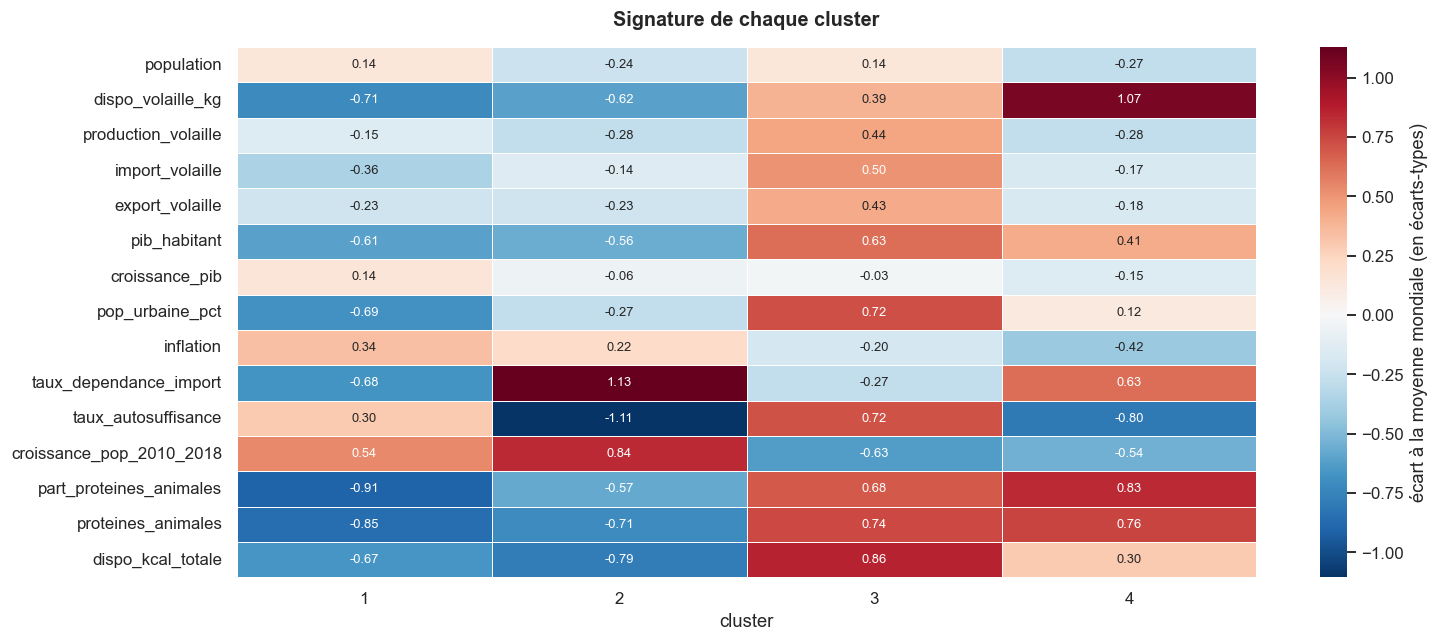

Lecture : rouge = nettement au-dessus de la moyenne mondiale
          bleu  = nettement en dessous


In [153]:
# --- 12.2 Écarts à la moyenne mondiale ---------------------------------------

moy_monde = df[VARS_PROFIL].mean()
ecarts = (df.groupby(CLUSTER)[VARS_PROFIL].mean() - moy_monde) / df[VARS_PROFIL].std()

plt.figure(figsize=(14, 6))
sns.heatmap(ecarts.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=.5, annot_kws={"size": 8.5},
            cbar_kws={"label": "écart à la moyenne mondiale (en écarts-types)"})
plt.title("Signature de chaque cluster", pad=14)
plt.xlabel("cluster"); plt.ylabel("")
plt.tight_layout()
plt.show()

print("Lecture : rouge = nettement au-dessus de la moyenne mondiale")
print("          bleu  = nettement en dessous")


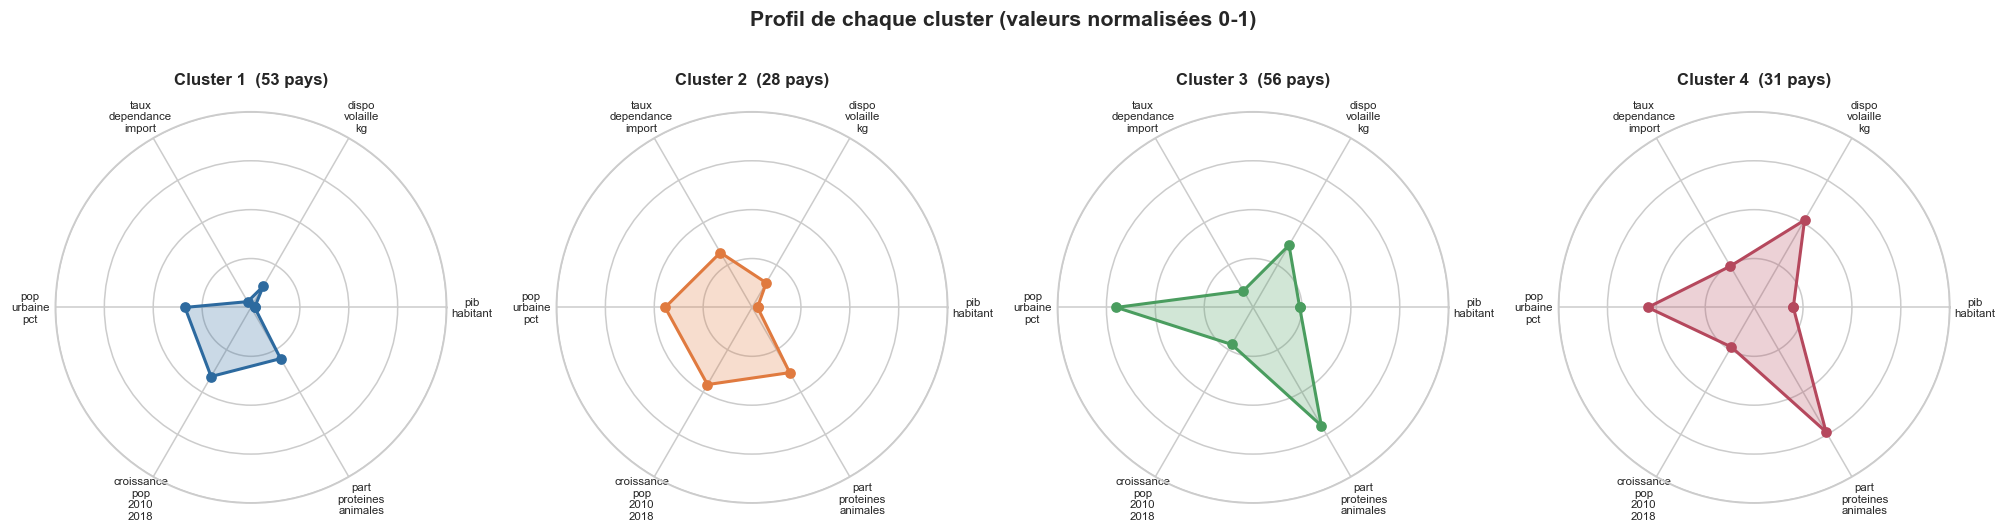

In [154]:
# --- 12.3 Profils en radar ----------------------------------------------------

VARS_RADAR = ["pib_habitant", "dispo_volaille_kg", "taux_dependance_import",
              "pop_urbaine_pct", "croissance_pop_2010_2018", "part_proteines_animales"]

norm = (df.groupby(CLUSTER)[VARS_RADAR].mean() - df[VARS_RADAR].min()) / \
       (df[VARS_RADAR].max() - df[VARS_RADAR].min())

angles = np.linspace(0, 2 * np.pi, len(VARS_RADAR), endpoint=False).tolist()
angles += angles[:1]

n_clusters = len(norm)
ncols = min(4, n_clusters)
nrows = int(np.ceil(n_clusters / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.8 * nrows),
                         subplot_kw=dict(polar=True))
axes = np.atleast_1d(axes).ravel()

for i, (c, ligne) in enumerate(norm.iterrows()):
    vals = ligne.tolist() + ligne.tolist()[:1]
    ax = axes[i]
    ax.plot(angles, vals, "o-", lw=2, color=PALETTE[i % len(PALETTE)])
    ax.fill(angles, vals, alpha=.25, color=PALETTE[i % len(PALETTE)])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([v.replace("_", "\n") for v in VARS_RADAR], size=7.5)
    ax.set_yticks([0, .25, .5, .75, 1]); ax.set_yticklabels([], size=7)
    ax.set_ylim(0, 1)
    ax.set_title(f"Cluster {c}  ({(df[CLUSTER]==c).sum()} pays)",
                 size=11, pad=18, fontweight="bold")
for ax in axes[n_clusters:]:
    ax.set_visible(False)
fig.suptitle("Profil de chaque cluster (valeurs normalisées 0-1)",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


In [155]:
# --- 12.4 Composition détaillée des clusters ---------------------------------

titre("12.4  COMPOSITION DES CLUSTERS")
for c in sorted(df[CLUSTER].unique()):
    sous = df[df[CLUSTER] == c].sort_values("population", ascending=False)
    print(f"\n{'='*78}")
    print(f"CLUSTER {c}  —  {len(sous)} pays  —  "
          f"{sous['population'].sum():,.0f} milliers d'habitants")
    print(f"{'='*78}")
    print(f"  PIB/hab moyen        : {sous['pib_habitant'].mean():>10,.0f} USD")
    print(f"  Conso volaille       : {sous['dispo_volaille_kg'].mean():>10.1f} kg/pers/an")
    print(f"  Dépendance import    : {sous['taux_dependance_import'].mean():>10.1f} %")
    print(f"  Croissance démo.     : {sous['croissance_pop_2010_2018'].mean():>10.1f} %")
    print(f"  Continents           : "
          f"{sous['continent'].value_counts().to_dict()}")
    print(f"\n  Pays : {', '.join(sous['pays'].tolist())}")


12.4  COMPOSITION DES CLUSTERS

CLUSTER 1  —  53 pays  —  3,436,582 milliers d'habitants
  PIB/hab moyen        :      2,485 USD
  Conso volaille       :        9.1 kg/pers/an
  Dépendance import    :       11.1 %
  Croissance démo.     :       17.9 %
  Continents           : {'Afrique': 27, 'Asie': 16, 'Amériques': 9, 'Europe': 1}

  Pays : Inde, Indonésie, Pakistan, Nigéria, Bangladesh, Éthiopie, Philippines, Égypte, Viet Nam, République-Unie de Tanzanie, Myanmar, Kenya, Algérie, Ouganda, Soudan, Afghanistan, Maroc, Venezuela (République bolivarienne du), Mozambique, Yémen, Népal, Madagascar, Cameroun, Côte d'Ivoire, Niger, Sri Lanka, Burkina Faso, Mali, Malawi, Guatemala, Zambie, Équateur, Cambodge, Sénégal, Tchad, Zimbabwe, Rwanda, Tunisie, Bolivie (État plurinational de), Azerbaïdjan, Jordanie, Honduras, Togo, Sierra Leone, Paraguay, Liban, El Salvador, Nicaragua, Turkménistan, République centrafricaine, République de Moldova, Eswatini, Belize

CLUSTER 2  —  28 pays  —  189,397 mi

---
## 13. Répartition géographique


13.1  CLUSTERS PAR CONTINENT


cluster_kmeans,1,2,3,4,Total
continent,,,,,
Afrique,27,16,1,1,45
Amériques,9,2,12,12,35
Asie,16,8,11,4,39
Europe,1,0,30,9,40
Océanie,0,2,2,5,9
Total,53,28,56,31,168


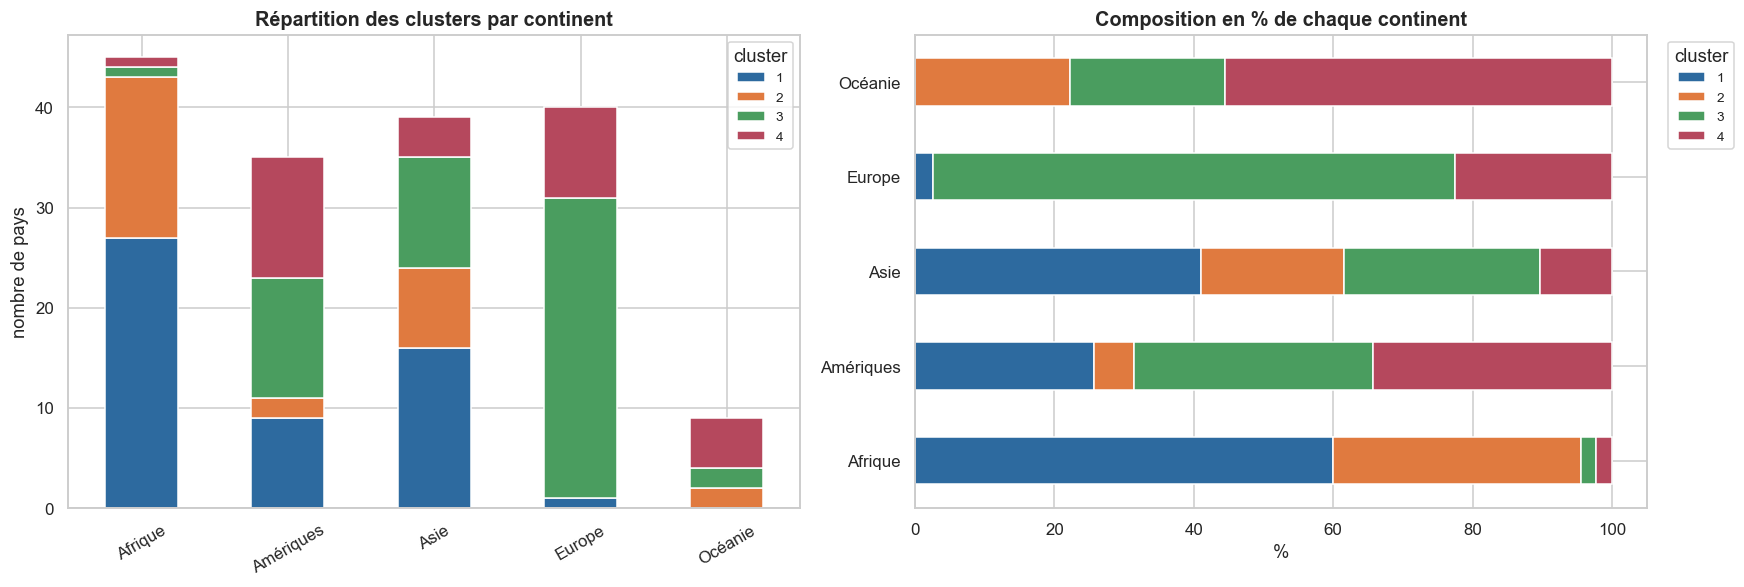

Un cluster n'est PAS un continent : la segmentation est économique et
alimentaire, pas géographique. C'est précisément l'intérêt de la démarche —
elle rapproche des pays que l'intuition géographique n'aurait pas associés.


In [156]:
# =============================================================================
# 13. RÉPARTITION GÉOGRAPHIQUE
# =============================================================================

croise = pd.crosstab(df["continent"], df[CLUSTER], margins=True, margins_name="Total")

titre("13.1  CLUSTERS PAR CONTINENT")
display(croise)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
pd.crosstab(df["continent"], df[CLUSTER]).plot(
    kind="bar", stacked=True, ax=axes[0], color=PALETTE[:K], edgecolor="white")
axes[0].set_title("Répartition des clusters par continent")
axes[0].set_xlabel(""); axes[0].set_ylabel("nombre de pays")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="cluster", fontsize=9)

(pd.crosstab(df["continent"], df[CLUSTER], normalize="index") * 100).plot(
    kind="barh", stacked=True, ax=axes[1], color=PALETTE[:K], edgecolor="white")
axes[1].set_title("Composition en % de chaque continent")
axes[1].set_xlabel("%"); axes[1].set_ylabel("")
axes[1].legend(title="cluster", fontsize=9, bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

print("Un cluster n'est PAS un continent : la segmentation est économique et")
print("alimentaire, pas géographique. C'est précisément l'intérêt de la démarche —")
print("elle rapproche des pays que l'intuition géographique n'aurait pas associés.")


---
## 14. Recommandations pour La poule qui chante

On construit un **score d'attractivité** à partir de critères explicites, pondérés selon
la stratégie de l'entreprise : un producteur de volaille **bio**, donc positionné sur un
produit à valeur ajoutée, qui cherche des marchés solvables et ouverts aux importations.

| Critère | Sens | Poids | Raison |
|---|---|---|---|
| Dépendance aux importations | ↑ favorable | 25 % | un pays qui importe déjà est un marché accessible |
| PIB par habitant | ↑ favorable | 25 % | le bio est un produit premium : il faut du pouvoir d'achat |
| Consommation de volaille/hab | ↑ favorable | 20 % | l'habitude de consommation existe déjà |
| Taille de la population | ↑ favorable | 10 % | volume potentiel |
| Croissance démographique | ↑ favorable | 10 % | marché de demain |
| Inflation | ↓ défavorable | 10 % | stabilité macro-économique |

> **Transparence méthodologique** : ces pondérations sont un **choix de l'analyste**,
> pas un résultat des données. Elles doivent être discutées avec le COMEX et peuvent être
> ajustées. C'est un outil d'aide à la décision, pas un verdict.


In [157]:
# =============================================================================
# 14. SCORE D'ATTRACTIVITÉ
# =============================================================================

def normaliser(s):
    """Ramène une série entre 0 et 1."""
    return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0

POIDS = {
    "taux_dependance_import":   ( 0.25, +1),
    "pib_habitant":             ( 0.25, +1),
    "dispo_volaille_kg":        ( 0.20, +1),
    "population":               ( 0.10, +1),
    "croissance_pop_2010_2018": ( 0.10, +1),
    "inflation":                ( 0.10, -1),
}

score = pd.Series(0.0, index=df.index)
for var, (poids, sens) in POIDS.items():
    base = df["log_" + var] if "log_" + var in df.columns else df[var]
    score += poids * normaliser(base) * sens if sens > 0 else poids * (1 - normaliser(base))

df["score_attractivite"] = (score * 100).round(1)

titre("14.1  SCORE D'ATTRACTIVITÉ MOYEN PAR CLUSTER")
sc = df.groupby(CLUSTER).agg(
    nb_pays=("pays", "size"),
    score_moyen=("score_attractivite", "mean"),
    pib_hab=("pib_habitant", "mean"),
    conso_volaille=("dispo_volaille_kg", "mean"),
    dependance_import=("taux_dependance_import", "mean"),
).round(1).sort_values("score_moyen", ascending=False)
display(sc)

CLUSTER_CIBLE = sc.index[0]
print(f"\nCluster le plus attractif : cluster {CLUSTER_CIBLE}")


14.1  SCORE D'ATTRACTIVITÉ MOYEN PAR CLUSTER


,nb_pays,score_moyen,pib_hab,conso_volaille,dependance_import
cluster_kmeans,,,,,
4,31,46.00,"22,406.30",37.30,78.90
3,56,43.60,"26,580.60",26.70,32.00
2,28,35.10,"3,522.80",10.60,104.90
1,53,27.60,"2,484.80",9.10,11.10



Cluster le plus attractif : cluster 4


14.2  TOP 20 DES PAYS PAR SCORE D'ATTRACTIVITÉ


,pays,continent,cluster_kmeans,score_attractivite,pib_habitant,dispo_volaille_kg,taux_dependance_import,population,croissance_pop_2010_2018
1,Chine - RAS de Hong-Kong,Asie,4,77.20,"46,160.43",53.51,323.93,"7,306.32",5.82
2,Émirats arabes unis,Asie,3,58.40,"43,733.62",43.47,105.10,"9,487.20",12.64
3,Belgique,Europe,3,57.90,"44,035.32",12.65,222.37,"11,419.75",4.97
4,Chine - RAS de Macao,Asie,4,57.90,"77,570.99",34.47,121.05,622.59,17.36
5,Koweït,Asie,4,57.60,"29,047.65",46.25,72.49,"4,056.10",38.28
6,États-Unis d'Amérique,Amériques,3,57.60,"60,047.72",55.68,0.67,"325,084.76",5.85
7,Israël,Asie,3,57.20,"41,013.26",67.39,0.00,"8,243.85",14.09
8,Pays-Bas,Europe,3,56.30,"49,513.68",20.33,163.44,"17,021.35",2.26
9,Arabie saoudite,Asie,3,54.90,"23,929.29",43.36,50.31,"33,101.18",22.91
10,Oman,Asie,2,54.80,"17,820.07",21.63,110.53,"4,665.93",58.79


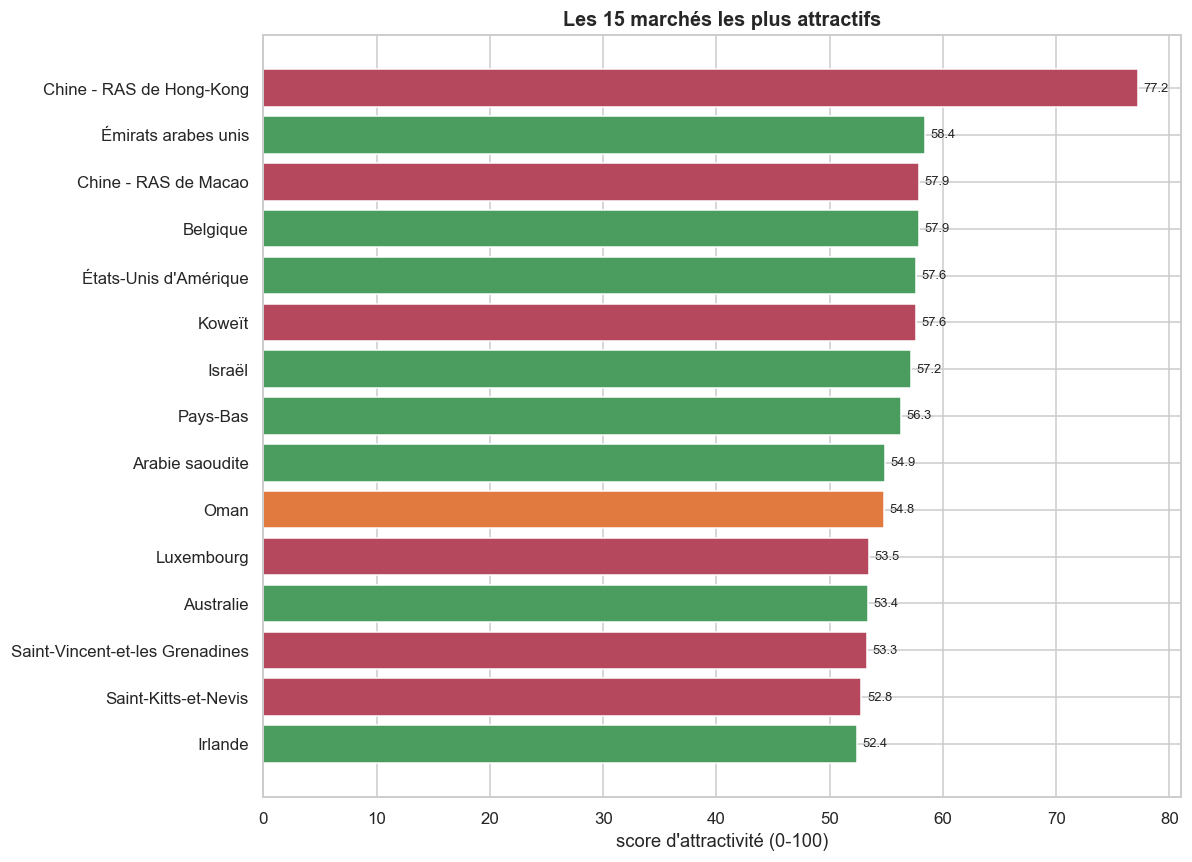

In [158]:
# --- 14.2 Classement des pays -------------------------------------------------

titre("14.2  TOP 20 DES PAYS PAR SCORE D'ATTRACTIVITÉ")
top = (df.nlargest(20, "score_attractivite")
         [["pays", "continent", CLUSTER, "score_attractivite", "pib_habitant",
           "dispo_volaille_kg", "taux_dependance_import", "population",
           "croissance_pop_2010_2018"]]
         .reset_index(drop=True))
top.index += 1
display(top)

plt.figure(figsize=(11, 8))
t15 = df.nlargest(15, "score_attractivite").sort_values("score_attractivite")
couleurs = [PALETTE[(c - 1) % len(PALETTE)] for c in t15[CLUSTER]]
plt.barh(t15["pays"], t15["score_attractivite"], color=couleurs, edgecolor="white")
plt.xlabel("score d'attractivité (0-100)")
plt.title("Les 15 marchés les plus attractifs")
for i, (p, s) in enumerate(zip(t15["pays"], t15["score_attractivite"])):
    plt.text(s + .5, i, f"{s:.1f}", va="center", fontsize=8.5)
plt.tight_layout()
plt.show()


In [159]:
# =============================================================================
# 14.2 bis  FILTRES D'ÉLIGIBILITÉ COMMERCIALE
# =============================================================================

titre("14.2 bis  DU SCORE STATISTIQUE AU SCORE COMMERCIAL")

FILTRES = {
    "population_min":  1_000,   # milliers d'hab. -> au moins 1 million
    "dependance_min":     10,   # en dessous, le pays produit l'essentiel de sa volaille
    "dependance_max":    100,   # au-dessus, c'est une plateforme de réexport
    "autosuffisance_max": 90,   # barrière à l'entrée trop élevée
}

df["eligible"] = (
    (df["population"]             >= FILTRES["population_min"])  &
    (df["taux_dependance_import"] >= FILTRES["dependance_min"])  &
    (df["taux_dependance_import"] <= FILTRES["dependance_max"])  &
    (df["taux_autosuffisance"]     < FILTRES["autosuffisance_max"])
)

print(f"Pays éligibles : {df['eligible'].sum()} sur {len(df)}\n")
for lib, msk in [
    ("marché trop petit (< 1 M hab.)",        df["population"] < FILTRES["population_min"]),
    ("quasi autosuffisant (import < 10 %)",   df["taux_dependance_import"] < FILTRES["dependance_min"]),
    ("plateforme de réexport (import > 100 %)", df["taux_dependance_import"] > FILTRES["dependance_max"]),
]:
    exclus = df.loc[msk, "pays"].tolist()
    print(f"  Exclus — {lib} : {len(exclus)}")
    print(f"      {', '.join(exclus[:12])}{' ...' if len(exclus) > 12 else ''}\n")

14.2 bis  DU SCORE STATISTIQUE AU SCORE COMMERCIAL
Pays éligibles : 55 sur 168

  Exclus — marché trop petit (< 1 M hab.) : 27
      Antigua-et-Barbuda, Bahamas, Barbade, Belize, Cabo Verde, Chine - RAS de Macao, Djibouti, Dominique, Fidji, Grenade, Guyana, Islande ...

  Exclus — quasi autosuffisant (import < 10 %) : 53
      Algérie, Argentine, Australie, Bangladesh, Belize, Bolivie (État plurinational de), Brésil, Burkina Faso, Bélarus, Cameroun, Chine, continentale, Colombie ...

  Exclus — plateforme de réexport (import > 100 %) : 17
      Belgique, Cabo Verde, Chine - RAS de Hong-Kong, Chine - RAS de Macao, Gambie, Lettonie, Mauritanie, Mongolie, Namibie, Oman, Pays-Bas, Saint-Vincent-et-les Grenadines ...



In [160]:
# --- Score recalibré sur les seuls pays éligibles -----------------------------

POIDS_CIBLE = {
    "taux_dependance_import":   (0.30, +1),   # le critère n°1 : le pays achète déjà dehors
    "dispo_volaille_kg":        (0.20, +1),   # l'habitude de consommation existe
    "pib_habitant":             (0.20, +1),   # le bio est un produit premium
    "croissance_pop_2010_2018": (0.15, +1),   # le marché de demain
    "population":               (0.10, +1),   # volume potentiel
    "inflation":                (0.05, -1),   # stabilité macro-économique
}

elig = df[df["eligible"]].copy()
sc = pd.Series(0.0, index=elig.index)
for var, (poids, sens) in POIDS_CIBLE.items():
    base = np.log1p(elig[var]) if var in ("pib_habitant", "population") else elig[var]
    n = normaliser(base)
    sc += poids * (n if sens > 0 else 1 - n)
elig["score_cible"] = (sc * 100).round(1)

df["score_cible"] = np.nan
df.loc[elig.index, "score_cible"] = elig["score_cible"]

titre("TOP 15 DES MARCHÉS CIBLES APRÈS FILTRAGE")
top = (elig.nlargest(15, "score_cible")
           [["pays", "continent", CLUSTER, "score_cible", "pib_habitant",
             "dispo_volaille_kg", "taux_dependance_import", "population",
             "croissance_pop_2010_2018"]].reset_index(drop=True))
top.index += 1
display(top)

TOP 15 DES MARCHÉS CIBLES APRÈS FILTRAGE


,pays,continent,cluster_kmeans,score_cible,pib_habitant,dispo_volaille_kg,taux_dependance_import,population,croissance_pop_2010_2018
1,Koweït,Asie,4,75.70,"29,047.65",46.25,72.49,"4,056.10",38.28
2,Gabon,Afrique,2,68.20,"6,921.73",29.33,97.44,"2,064.82",30.49
3,Arabie saoudite,Asie,3,66.10,"23,929.29",43.36,50.31,"33,101.18",22.91
4,Iraq,Asie,2,62.70,"4,759.28",14.95,83.04,"37,552.78",29.22
5,Irlande,Europe,3,62.70,"72,161.40",25.82,77.34,"4,753.28",5.80
6,Congo,Afrique,2,59.60,"2,211.63",21.53,94.55,"5,110.69",22.71
7,Cuba,Amériques,4,58.30,"8,610.61",23.72,91.23,"11,339.25",1.00
8,Angola,Afrique,2,56.10,"2,832.15",10.56,86.83,"29,816.77",31.91
9,Autriche,Europe,3,54.60,"47,163.74",18.20,63.58,"8,819.90",5.72
10,Macédoine du Nord,Europe,4,54.10,"5,955.30",19.73,97.56,"2,082.00",0.59


In [161]:
# --- 14.3 Recommandation finale -----------------------------------------------

titre("14.3  RECOMMANDATION")

cible = df[df[CLUSTER] == CLUSTER_CIBLE].nlargest(10, "score_attractivite")

print(f"CLUSTER RECOMMANDÉ : cluster {CLUSTER_CIBLE}")
print(f"   {len(df[df[CLUSTER]==CLUSTER_CIBLE])} pays | "
      f"{df[df[CLUSTER]==CLUSTER_CIBLE]['population'].sum():,.0f} milliers d'habitants")
print()
print("Profil du cluster :")
p = df[df[CLUSTER] == CLUSTER_CIBLE]
print(f"   PIB par habitant moyen     : {p['pib_habitant'].mean():>10,.0f} USD")
print(f"   Consommation de volaille   : {p['dispo_volaille_kg'].mean():>10.1f} kg/pers/an")
print(f"   Dépendance aux importations: {p['taux_dependance_import'].mean():>10.1f} %")
print(f"   Taux d'autosuffisance      : {p['taux_autosuffisance'].mean():>10.1f} %")
print(f"   Croissance démographique   : {p['croissance_pop_2010_2018'].mean():>10.1f} %")
print()
print("TOP 10 DES PAYS À CIBLER EN PRIORITÉ :\n")
for i, (_, r) in enumerate(cible.iterrows(), 1):
    print(f"  {i:>2}. {r['pays']:32s} score {r['score_attractivite']:>5.1f}  |  "
          f"PIB/hab {r['pib_habitant']:>9,.0f} USD  |  "
          f"conso {r['dispo_volaille_kg']:>5.1f} kg  |  "
          f"import {r['taux_dependance_import']:>5.1f} %")


14.3  RECOMMANDATION
CLUSTER RECOMMANDÉ : cluster 4
   31 pays | 47,051 milliers d'habitants

Profil du cluster :
   PIB par habitant moyen     :     22,406 USD
   Consommation de volaille   :       37.3 kg/pers/an
   Dépendance aux importations:       78.9 %
   Taux d'autosuffisance      :       37.1 %
   Croissance démographique   :        5.8 %

TOP 10 DES PAYS À CIBLER EN PRIORITÉ :

   1. Chine - RAS de Hong-Kong         score  77.2  |  PIB/hab    46,160 USD  |  conso  53.5 kg  |  import 323.9 %
   2. Chine - RAS de Macao             score  57.9  |  PIB/hab    77,571 USD  |  conso  34.5 kg  |  import 121.1 %
   3. Koweït                           score  57.6  |  PIB/hab    29,048 USD  |  conso  46.2 kg  |  import  72.5 %
   4. Luxembourg                       score  53.5  |  PIB/hab   110,193 USD  |  conso  18.3 kg  |  import 100.0 %
   5. Saint-Vincent-et-les Grenadines  score  53.3  |  PIB/hab     7,988 USD  |  conso  72.3 kg  |  import 112.5 %
   6. Saint-Kitts-et-Nevis        

### Trame de la recommandation pour le COMEX

> ⚠️ **À compléter après exécution** avec les noms de pays réellement obtenus.

**Ce que dit l'analyse.** Les 169 pays se répartissent en 4 groupes cohérents, qui ne
recoupent pas les frontières géographiques. Un de ces groupes concentre les marchés
solvables, urbanisés, déjà consommateurs de volaille et structurellement dépendants
des importations.

**Recommandation en trois horizons :**

| Horizon | Cible | Logique |
|---|---|---|
| **Court terme** | les 3 premiers pays du classement | tester le marché sur des cibles à fort score et risque faible |
| **Moyen terme** | le reste du cluster recommandé | déployer si le test est concluant |
| **À écarter** | les pays fortement autosuffisants | barrière à l'entrée trop élevée, concurrence locale installée |

**Limites à annoncer au COMEX** — c'est ce qui distingue une analyse honnête :

- les données datent de **2017**, seule année disponible dans les bilans FAO ;
- l'analyse ne prend en compte **ni les barrières douanières, ni les accords commerciaux,
  ni les certifications bio locales**, qui peuvent être bloquantes ;
- le score d'attractivité repose sur des **pondérations choisies**, à valider ;
- l'étape suivante est une **étude de marché terrain** sur les 3 pays retenus.

### Réponse de soutenance — *« Y a-t-il un pays qui ressort plus que les autres ? »*

> Oui, mais la bonne réponse n'est pas un nom isolé. L'analyse fait émerger un **groupe**
> de pays au profil homogène, et à l'intérieur de ce groupe un classement par score.
> Recommander un seul pays serait fragile : si l'implantation échoue pour une raison locale,
> il n'y a pas de plan B. Recommander un cluster permet de sécuriser la stratégie et de
> déployer par vagues.


---
## 15. Export des résultats


In [127]:
# =============================================================================
# 15. EXPORT
# =============================================================================

resultats = df[["pays", "iso3", "continent", "cluster_cah", "cluster_kmeans",
                "score_attractivite"] + VARS_PROFIL].copy()
for i in range(N_AXES):
    resultats[f"F{i+1}"] = coords[:, i].round(3)

resultats = resultats.sort_values("score_attractivite", ascending=False)
resultats.to_csv(CLEAN + "resultats_clustering.csv", index=False, encoding="utf-8")
profil.T.to_csv(CLEAN + "profils_clusters.csv", encoding="utf-8")

titre("15.  EXPORTS RÉALISÉS")
print(f"   {CLEAN}resultats_clustering.csv   ({resultats.shape[0]} pays x {resultats.shape[1]} colonnes)")
print(f"   {CLEAN}profils_clusters.csv")
print()
display(resultats.head(15))


15.  EXPORTS RÉALISÉS
   ../Data/clean/resultats_clustering.csv   (168 pays x 25 colonnes)
   ../Data/clean/profils_clusters.csv



,pays,iso3,continent,cluster_cah,cluster_kmeans,score_attractivite,population,dispo_volaille_kg,production_volaille,import_volaille,export_volaille,pib_habitant,croissance_pib,pop_urbaine_pct,inflation,taux_dependance_import,taux_autosuffisance,croissance_pop_2010_2018,part_proteines_animales,proteines_animales,dispo_kcal_totale,F1,F2,F3,F4
31,Chine - RAS de Hong-Kong,HKG,Asie,1,4,77.20,"7,306.32",53.51,24.00,907.00,663.00,"46,160.43",3.80,100.00,1.49,323.93,8.57,5.82,73.32,101.10,"3,353.00",5.29,-3.65,2.50,2.71
163,Émirats arabes unis,ARE,Asie,1,3,58.40,"9,487.20",43.47,48.00,433.00,94.00,"43,733.62",-1.06,84.69,1.97,105.10,11.65,12.64,40.88,43.85,"3,370.00",2.53,-1.22,2.25,0.46
32,Chine - RAS de Macao,MAC,Asie,1,4,57.90,622.59,34.47,3.00,23.00,0.00,"77,570.99",9.92,100.00,1.23,121.05,15.79,17.36,66.84,67.09,"2,999.00",2.07,-3.19,-0.68,1.35
16,Belgique,BEL,Europe,1,3,57.90,"11,419.75",12.65,463.00,338.00,656.00,"44,035.32",1.47,86.67,2.13,222.37,304.61,4.97,57.12,57.89,"3,770.00",4.37,1.24,0.89,1.75
165,États-Unis d'Amérique,USA,Amériques,1,3,57.60,"325,084.76",55.68,"21,914.00",123.00,"3,692.00","60,047.72",2.46,80.40,2.13,0.67,119.97,5.85,65.04,73.89,"3,762.00",5.36,2.53,0.42,-0.13
80,Koweït,KWT,Asie,1,4,57.60,"4,056.10",46.25,56.00,137.00,4.00,"29,047.65",-4.71,100.00,2.17,72.49,29.63,38.28,47.56,47.41,"3,445.00",1.89,-1.53,2.71,-0.72
71,Israël,ISR,Asie,1,3,57.20,"8,243.85",67.39,629.00,0.00,3.00,"41,013.26",4.34,91.67,0.25,0.00,98.90,14.09,59.18,72.57,"3,507.00",3.18,-0.13,-1.64,-1.56
115,Pays-Bas,NLD,Europe,1,3,56.30,"17,021.35",20.33,"1,100.00",608.00,"1,418.00","49,513.68",2.78,91.12,1.38,163.44,295.70,2.26,65.55,68.45,"3,251.00",4.84,1.64,0.60,1.41
7,Arabie saoudite,SAU,Asie,1,3,54.90,"33,101.18",43.36,616.00,722.00,10.00,"23,929.29",1.18,83.30,-0.83,50.31,42.93,22.91,42.28,37.00,"3,194.00",1.89,0.09,1.83,0.68
110,Oman,OMN,Asie,4,2,54.80,"4,665.93",21.63,7.00,126.00,16.00,"17,820.07",0.30,78.31,1.59,110.53,6.14,58.79,49.62,42.20,"2,924.00",0.01,-1.89,2.68,1.33


---
## Synthèse du livrable 2

| Étape | Décision | Justification |
|---|---|---|
| Centrage-réduction | appliqué à toutes les variables | unités et ordres de grandeur incomparables ; sans cela le PIB écraserait l'ACP |
| Nombre d'axes ACP | 4 | convergence des critères de Kaiser, du coude et de la variance cumulée |
| Support du clustering | composantes de l'ACP | variables décorrélées, bruit réduit, lisibilité accrue — vérifié par comparaison avec les données brutes |
| Méthode 1 | CAH de Ward | fournit le dendrogramme, qui suggère le nombre de groupes sans le présupposer |
| Méthode 2 | k-means | optimisation itérative, permet de rattraper les affectations sous-optimales de la CAH |
| Nombre de clusters | 4 | coude, silhouette, **et** lisibilité pour un COMEX |
| Convergence | mesurée par l'indice de Rand ajusté | les divergences se concentrent sur les pays frontières, à faible silhouette |

### Pour préparer la soutenance

Les questions attendues et leurs réponses sont rédigées dans les cellules Markdown des
sections 7, 10, 11 et 14. Relis-les et adapte-les à tes chiffres réels avant l'oral.
